# Constraint-Aware Auditing of Fairness Gains in Tabular-to-Graph Learning

**Group 14 · Team Mozzarella · Project 10 · PW26 AI Governance elective · Target journal: *Knowledge-Based Systems* (Elsevier)**
Anchor paper: Li, Cheng, Zhang & Zhang (2024), *Contrastive learning for fair graph representations via counterfactual graph augmentation*, KBS 305:112635, [doi:10.1016/j.knosys.2024.112635](https://doi.org/10.1016/j.knosys.2024.112635)

Fair graph neural networks are routinely evaluated on **German Credit** and **Credit Default**. Both are tables, and their "graphs" are *engineered* kNN similarity relations. This notebook asks whether reported fairness gains are properties of the methods or artefacts of undocumented graph construction. It contributes a **constraint-aware edge-admissibility audit** with three declared, checkable constraints:
- a screened-space neighbour rank in a non-sensitive feature space;
- a training-calibrated distance ceiling;
- a degree cap.

It also contributes a **validation-locked graph-selection procedure** built on that audit.

## Research questions
| RQ | Question |
|---|---|
| **RQ1 · Construction dependence** | When credit records are converted into kNN similarity graphs, how much do the **sign and magnitude** of the equalized-odds gains of fairness-aware GCNs (relative to an otherwise identical GCN) vary across graph families, neighbourhood sizes and attribute spaces, and do the graph models keep any utility advantage over tabular models? |
| **RQ2 · Recoverable audit-group information** | With the group-defining field excluded from predictive inputs, how does held-out audit-group predictability vary between **node inputs and propagated features**, and how do group error gaps change under crossed removal of associated fields from predictive inputs, graph distances, or both? |
| **RQ3 · Edge-admissibility audit** | Can declared admissibility constraints (screened-space neighbour rank, distance ceiling, degree cap) identify edges unsupported by the declared non-sensitive feature-space rules? Do models trained or evaluated on admissible edges change group error gaps differently from **matched random edge removal**? |
| **RQ4 · Validation-locked graph selection** | Under the method-relative validation utility budget, with audit-selector relaxations explicitly reported, how do the three existing selectors compare in held-out utility and group error gaps? |
| **RQ5 · Persistence of fairness claims** | Which fairness gains, measured against both a plain GCN and a graph-free MLP, persist under **inference on new applicants (inductive)**, edge deletion without retraining, and portability of a source-selected graph recipe to a **second dataset** with separately fitted models? |

Each question can return a meaningful negative result. None of them requires a claim of causal or counterfactual fairness.

## Results produced (displayed here, saved as PDF/CSV, zipped at the end)
| RQ | Outputs |
|---|---|
| RQ1 | Table 1 graph multiverse statistics · Figure 1 gain heat map · Figure 2 specification curve · Table 2 construction envelope, rank stability and variance decomposition |
| RQ2 | Table 3 associated-field screening · Figure 3 excess sensitive homophily · Figure 4 sensitive-information probes · Table 4 crossed feature × topology ablation |
| RQ3 | Figure 5 legitimacy-rank distribution · Table 5 admissibility audit card · Figure 6 retrained admissible vs matched-random graphs · Table 6 fixed-model edge interventions |
| RQ4 | Table 7 validation-locked selection · Figure 7 validation–test agreement · Figure 8 utility-budget sensitivity · Table 8 selection stability and test-oracle regret |
| RQ5 | Figure 9 transductive → inductive accuracy–fairness plane · Figure 10 edge deletion without retraining · Table 9 cross-dataset agreement and transfer · Table 10 persistence matrix with bootstrap intervals |
| Supporting | S1 provenance · S2 cohorts and group support · S3 reference-configuration results (anchor-style) · S4 method verification |

## Methodology (executed in this order)
- **M1 Acquisition and provenance.** Download UCI 144 and 350 (CC BY 4.0), record SHA-256 and assert the documented shapes.
- **M2 Cohorts, outcomes, groups.**
  - German: all 1,000 records, for a separate benchmark-grouping sensitivity analysis. G=1 means Attribute 9=A92; G=0 means any other code. These are not verified female/male memberships. The whole Attribute 9 is excluded from predictive inputs and non-full graph spaces.
  - Credit (primary documented-SEX audit): fixed stratified 5,000 subset (outcome × sex, seed 20261026); this differs from the anchor paper's age-based Credit groups and full cohort. ID, SEX and target are excluded from features.
  - The favourable outcome is coded 1.
- **M3 Splits and training-only preprocessing.** Five person-level 60/20/20 splits (seeds 11, 23, 37, 47, 59), stratified by outcome × group. Encoders and scalers are fit on training persons only, and Credit repayment-status codes are treated as categorical.
- **M4 Associated-field screening.** Training-only 5-fold CV AUC and NMI of every field for the dataset-specific audit group. The top 3 fields form the *associated* set. This is a statistical association, not a causal proxy.
- **M5 Label-free graph construction.**
  - Attribute spaces: *full* (+ standardised audit-group indicator, diagnostic), *unaware* (group field removed), *legit* (group-defining and associated fields removed; screened, not ethically certified).
  - Families: *union* kNN, *mutual* kNN, *admissible* (constraint-filtered union).
  - k ∈ {5, 15, 30}, Euclidean distance.
  - Outcome labels never enter graph construction.
- **M6 Admissibility constraints.** An edge is admissible iff:
  - (i) its normalised screened-space neighbour rank min(rank_i(j), rank_j(i))/k ≤ κ = 2 in the legit space;
  - (ii) its distance is within the training-only 95th percentile of union edge distances;
  - (iii) both endpoints respect a degree cap of 2k, with edges processed in distance order.
  - Audit/base graph isolation is reported and never repaired. CFA training-view augmentation separately repairs isolated nodes and is not guaranteed to preserve the base graph constraints.
- **M7 Models.** Majority, logistic regression, MLP, histogram gradient boosting (HGB), GCN, GCN-SP (statistical-parity penalty), GCN-EO (soft equalized-odds penalty) and CFA-GCN (mechanism-inspired approximation: group-conditioned views + sampled-node InfoNCE + a linear adversary; OPT omitted; author-code availability not verified in this review). Training uses a class-balanced loss, the same two-layer encoder architecture with separately fitted parameters, and early stopping on the validation objective.
- **M8 Metrics.**
  - Utility: balanced accuracy (primary), accuracy, AUC, F1.
  - Fairness: **EOdds gap** = max(|ΔTPR|, |ΔFPR|) (primary), ΔEO (TPR gap, as in the anchor paper) and ΔSP.
  - Gains are paired per split. Intervals are 95% t-intervals over 5 splits, which are descriptive because the splits overlap.
- **M9 Residual information.** Linear probes for the dataset-specific audit group at 0, 1 and 2 propagation hops, plus a crossed 2 × 2 ablation that removes the associated fields from node features and/or graph distances.
- **M10 Audit interventions.**
  - Retrain on admissible graphs versus three density-matched random graphs per dataset/split/space/k (two in quick mode); average draws within each split before intervals.
  - Hold the trained model fixed and apply each constraint alone and all together, versus matched random deletion (3 draws).
- **M11 Validation-locked selection.** Three selectors use validation data only:
  - utility-only;
  - fairness-only within a 2 pp balanced-accuracy floor;
  - constraint-audit: admissible family; ranks spaces by worst validation EOdds over all admissible k, then picks an individually utility-feasible recipe. If none is feasible, it automatically relaxes the floor and reports the validation shortfall.
  - Selector diagnostics: within-split rank agreement between validation and test metrics, sensitivity to the utility budget (0.5–8 pp), stability of the chosen recipe across splits, and regret against a test oracle that has the same budget.
- **M12 Deployment and persistence.**
  - Strict inductive inference: the reference graph contains training persons only; validation/test persons receive messages from references, with no feedback.
  - Random edge deletion (0–50%) without retraining, with shared masks for paired models.
  - Cross-dataset recipe portability: select by highest mean source-validation EOdds gain over matched GCN, without a utility constraint; reuse separately fitted destination runs for that recipe. No weights or edges are transferred and no destination-based recipe reselection occurs. Group definitions differ.
  - Stratified person bootstrap (within outcome × group cells) on the primary split.
- **M13 Verification and synthesis.** Built-in checks (symmetry, constraints, inductive isolation, reproducibility of retraining), auto-generated key findings, manifest and zip.

> **Scope.** Earlier exploratory runs informed this design. Configuration is declared at run start, and recipe selection uses validation metrics exclusively. Test metrics are computed for reporting and never used to select a deployable recipe. Edges are engineered similarity, not social relations. Perturbing them does not establish causal or counterfactual fairness. Splits overlap, so intervals are descriptive, and no confirmatory p-values are claimed across this exploratory grid.
## Working revision v3 · 4 November 2026
The 27-recipe grid, four graph methods, per-space distance ceiling and three original selectors are retained. Additions address specific RQ comparisons: HGB (three leaf-count candidates, validation balanced-accuracy selection only), repeated random retraining, per-filter matched fixed-model controls, direct paired audit-minus-random effects (S5), an objective-controlled selector ablation with strict abstention when infeasible (S6), and a limited topology-only structural probe (S7). Table 10 adds the HGB comparator. These additions strengthen evaluation; they do not constitute a new state-of-the-art fair-GNN algorithm. The Assignment 1 submission remains a separate frozen, output-free snapshot. Quick-mode outputs are smoke tests, not final evidence.

### Cell 1 · Environment, locked configuration and output folders · RQ1–RQ5
**What it does:** imports the scientific stack and declares the configuration for this run in one `CFG` dictionary. Earlier exploratory work informed the design; this is not an independently preregistered analysis. It also creates the output folders, defines the plotting style (fixed colour per method; the vanilla GCN is the dark reference) and defines the save helpers.
**Main step:** set-up for M1–M13. `P10_QUICK=1` runs a reduced smoke test, and `P10_JOBS` sets the number of parallel workers (default: up to 4 CPU cores).

In [1]:
import os, json, time, hashlib, zipfile, warnings, urllib.request, copy, platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy import sparse, stats
from scipy.sparse.csgraph import connected_components
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from joblib import Parallel, delayed
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             normalized_mutual_info_score, pairwise_distances)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
torch.set_num_threads(1)  # configured CPU thread limit; current-revision timing remains unverified

QUICK = os.environ.get("P10_QUICK", "0") == "1"
CFG = dict(
    revision="v3_rq_controls_2026-11-04",
    group="Mozzarella",
    seeds=[11, 23, 37, 47, 59] if not QUICK else [11, 23],   # person-level splits
    primary_seed=11,                                          # prespecified split for bootstrap and edge samples
    spaces=["full", "unaware", "legit"],                      # attribute space used to compute graph distances
    families=["union", "mutual", "admissible"],
    k_grid=[5, 15, 30] if not QUICK else [5, 15],
    ref_k=15,                                                 # k for probes, ablation, interventions, reference table
    n_assoc=3,                                                # associated fields removed in the legit space
    kappa=2, dist_quantile=0.95, degree_mult=2,               # admissibility constraints
    split=(0.6, 0.2, 0.2),
    hidden=32, dropout=0.3, lr=1e-2, weight_decay=5e-4,
    epochs=200 if not QUICK else 40, patience=20,
    lambda_sp=1.0, lambda_eo=5.0,
    cfa=dict(alpha=0.4, tau=0.4, beta=0.5, gamma=1.0, gp=1.0, n_contrast=512),
    utility_tol=2.0,                                          # balanced-accuracy floor (pp) for selectors
    budget_grid=[0.5, 1.0, 2.0, 4.0, 8.0],                    # floors scanned in the RQ4 sensitivity analysis
    drop_rates=[0.0, 0.1, 0.25, 0.5] if not QUICK else [0.0, 0.25],
    drop_repeats=3 if not QUICK else 2,
    retrain_random_draws=3 if not QUICK else 2,
    hgb_leaf_grid=[7, 15, 31], hgb_iterations=200 if not QUICK else 60,
    n_boot=1000 if not QUICK else 200,
    subset_n=5000, subset_seed=20261026,
)
N_JOBS = int(os.environ.get("P10_JOBS", min(4, os.cpu_count() or 1)))
TAB = ["Majority", "LogReg", "MLP", "HGB"]
GNN = ["GCN", "GCN-SP", "GCN-EO", "CFA-GCN"]
FAIR = ["GCN-SP", "GCN-EO", "CFA-GCN"]
SELECTORS = ["utility_only", "fairness_only", "constraint_audit"]

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
OUT = WORK / "p10_outputs"
FIG_DIR, TAB_DIR, RAW_DIR = OUT / "figures", OUT / "tables", OUT / "raw_results"
DATA_DIR = WORK / "p10_data"
for d in (FIG_DIR, TAB_DIR, RAW_DIR, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Plot style: fixed colour per method (never re-assigned), recessive axes, ordinal ramp for attribute spaces
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4df"
METHOD_COLOR = {"GCN": "#3a3936", "GCN-SP": "#2a78d6", "GCN-EO": "#eb6834", "CFA-GCN": "#1baf7a",
                "MLP": "#8a8984", "LogReg": "#b0afa9", "Majority": "#cfcec8", "HGB": "#a95b95"}
METHOD_MARKER = {"GCN": "o", "GCN-SP": "s", "GCN-EO": "^", "CFA-GCN": "D", "MLP": "P", "LogReg": "X", "Majority": "*", "HGB": "v"}
SPACE_COLOR = {"full": "#104281", "unaware": "#2a78d6", "legit": "#86b6ef"}
# Legacy keys are retained for compatibility; "legit" means screened, not ethically legitimate.
SPACE_LABEL = {"full": "Full (+ audit group)", "unaware": "Unaware (group field removed)",
               "legit": "Screened (group field + associated fields removed)"}
GROUP_LABEL = {"Credit": "documented SEX category", "German": "legacy A92-vs-other grouping"}
GROUP_DESCRIPTION = {
    "Credit": "Primary audit: S=1 for documented SEX=2, S=0 for SEX=1; historical recorded categories",
    "German": "Sensitivity analysis: G=1 for Attribute9=A92, G=0 otherwise; not verified female/male membership",
}
FAMILY_STYLE = {"union": "-", "mutual": "--", "admissible": ":"}
SELECTOR_COLOR = {"utility_only": "#52514e", "fairness_only": "#7b5cc4", "constraint_audit": "#c98a12"}
DIV = LinearSegmentedColormap.from_list("gain", ["#a32b2b", "#e66767", "#f0efec", "#5598e7", "#104281"])  # red = loss, blue = gain
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42, "font.size": 9,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "figure.facecolor": "white",
})

MANIFEST = []

def log(msg):
    print(f"[{(time.time() - T0) / 60:.1f} min] {msg}", flush=True)

def save_fig(fig, fid, title):
    path = FIG_DIR / f"{fid}.pdf"
    fig.savefig(path, bbox_inches="tight")
    MANIFEST.append(dict(id=fid, kind="figure", file=str(path.relative_to(OUT)), title=title))
    plt.show()
    log(f"saved {fid}")

def save_table(df, fid, title, show=None):
    # Dataset-specific interpretation travels with generated tables.
    if "dataset" in df.columns:
        df = df.assign(group_definition=df["dataset"].map(GROUP_DESCRIPTION))
    path = TAB_DIR / f"{fid}.csv"
    df.to_csv(path, index=False)
    MANIFEST.append(dict(id=fid, kind="table", file=str(path.relative_to(OUT)), title=title))
    display(Markdown(f"**{fid}.** {title}"))
    display(show if show is not None else df)
    log(f"saved {fid}")

def ci(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 2:
        return (x.mean() if len(x) else np.nan), np.nan
    return x.mean(), stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))

def fmt(x, digits=2):
    m, h = ci(x)
    return f"{m:.{digits}f}" if np.isnan(h) else f"{m:.{digits}f} ± {h:.{digits}f}"

T0 = time.time()
print(f"Group {CFG['group']} | QUICK={QUICK} | workers={N_JOBS} | Kaggle={ON_KAGGLE} | outputs -> {OUT}")
print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__} | torch {torch.__version__} | cpus {os.cpu_count()}")

Group Mozzarella | QUICK=False | workers=4 | Kaggle=True | outputs -> /kaggle/working/p10_outputs
python 3.13.18 | numpy 2.1.3 | pandas 2.3.3 | sklearn 1.6.1 | torch 2.11.0+cpu | cpus 4


### Cell 2 · Data acquisition and provenance (M1) · RQ1–RQ5
**What it does:** downloads the UCI CSV exports of German Credit (UCI 144) and Credit Default (UCI 350). On Kaggle, *Internet* must be on. Offline, the cell falls back to any CSV with the right header under `/kaggle/input`. It records the source, DOI, licence, SHA-256 and shape, and asserts the shapes documented by UCI.
**Main step:** M1, which provides the data-access evidence for Checkpoint 2 (**Table S1**).

In [2]:
UCI = {
    "German": dict(uci_id=144, url="https://archive.ics.uci.edu/static/public/144/data.csv",
                   doi="10.24432/C5NC77", licence="CC BY 4.0", shape=(1000, 21), first_col="Attribute1"),
    "Credit": dict(uci_id=350, url="https://archive.ics.uci.edu/static/public/350/data.csv",
                   doi="10.24432/C55S3H", licence="CC BY 4.0", shape=(30000, 25), first_col="ID"),
}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def fetch(name, src):
    path, origin = DATA_DIR / f"uci_{src['uci_id']}.csv", src["url"]
    if not path.exists():
        try:
            req = urllib.request.Request(src["url"], headers={"User-Agent": "p10-research-notebook"})
            with urllib.request.urlopen(req, timeout=120) as r:
                path.write_bytes(r.read())
        except Exception as err:
            hits = [p for p in Path("/kaggle/input").rglob("*.csv")
                    if p.open().readline().startswith(src["first_col"] + ",")] if Path("/kaggle/input").exists() else []
            if not hits:
                raise RuntimeError(f"Could not download {name} ({err}). Enable Internet or attach the UCI CSV.") from err
            path, origin = hits[0], f"kaggle input: {hits[0]}"
    df = pd.read_csv(path)
    assert df.shape == src["shape"], f"{name}: shape {df.shape} != UCI documentation {src['shape']}"
    return df, dict(dataset=name, uci_id=src["uci_id"], doi=src["doi"], licence=src["licence"], source=origin,
                    rows=df.shape[0], columns=df.shape[1], sha256=sha256_file(path),
                    retrieved_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"))

RAW, prov = {}, []
for name, src in UCI.items():
    RAW[name], rec = fetch(name, src)
    prov.append(rec)
save_table(pd.DataFrame(prov), "TableS1_data_provenance", "Data access and provenance (UCI, CC BY 4.0)")

**TableS1_data_provenance.** Data access and provenance (UCI, CC BY 4.0)

,dataset,uci_id,doi,licence,source,rows,columns,sha256,retrieved_utc,group_definition
0,German,144,10.24432/C5NC77,CC BY 4.0,https://archive.ics.uci.edu/static/public/144/...,1000,21,f985b42636c9e28ce4fb3913738d1ebfd0f7947fda8d44...,2026-11-04T17:45:40+00:00,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
1,Credit,350,10.24432/C55S3H,CC BY 4.0,https://archive.ics.uci.edu/static/public/350/...,30000,25,45bcf4df62ff2e237a74eb155cabfb4bbbc171219a0637...,2026-11-04T17:45:40+00:00,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[0.0 min] saved TableS1_data_provenance


### Cell 3 · Cohorts, outcomes and audit groups (M2) · RQ1–RQ5
Credit Default is the primary audit using its documented SEX field (S=1 for SEX=2; S=0 for SEX=1).
German Credit is a separate benchmark sensitivity analysis: G=1 for Attribute9=A92 and G=0 otherwise. Neither German group is described as verified female/male membership. The whole Attribute9 is excluded from predictive inputs. South German Credit documents the same underlying cohort, not a new cohort.
The fixed Credit subset, ID-hash assertion, outcome coding, monetary transforms and existing unknown-category recoding are retained. Hash agreement and source values are checked at runtime.

In [3]:
GERMAN_COLUMNS = ["checking_status", "duration_months", "credit_history", "purpose", "credit_amount",
                  "savings_status", "employment_since", "installment_rate", "personal_status_sex",
                  "other_debtors", "residence_since", "property", "age", "other_installment_plans",
                  "housing", "existing_credits", "job", "num_dependents", "telephone", "foreign_worker", "class"]
CREDIT_NAMES = {"X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION", "X4": "MARRIAGE", "X5": "AGE",
                **{f"X{i}": n for i, n in zip(range(6, 12), ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"])},
                **{f"X{i}": f"BILL_AMT{i - 11}" for i in range(12, 18)},
                **{f"X{i}": f"PAY_AMT{i - 17}" for i in range(18, 24)}}
EXPECTED_SUBSET_IDS_SHA256 = "d7873e5f2f1e25d2f7f1c46b3283b73e3f32a7d14037265146b1292a4351722f"

def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

def prep_german(raw):
    df = raw.copy(); df.columns = GERMAN_COLUMNS
    print("German Attribute 9 codes:", df.personal_status_sex.value_counts().sort_index().to_dict(), "(A95 absent)")
    X = df.drop(columns=["class", "personal_status_sex"]).copy()
    X["credit_amount"] = np.log1p(X["credit_amount"])
    cat = ["checking_status", "credit_history", "purpose", "savings_status", "employment_since", "other_debtors",
           "property", "other_installment_plans", "housing", "job", "telephone", "foreign_worker"]
    return dict(name="German", X=X, cat=cat, ids=np.arange(1, len(df) + 1),
                s=(df.personal_status_sex == "A92").astype(int).to_numpy(),
                y=(df["class"] == 1).astype(int).to_numpy(), sens="legacy grouping G=1 (Attribute 9 = A92), not verified sex",
                group_names={0: "G=0: Attribute9 != A92", 1: "G=1: Attribute9 = A92"},
                label="good credit")

def prep_credit(raw):
    strata = raw[["Y", "X2"]].astype(str).agg("_".join, axis=1)
    sub, _ = train_test_split(raw, train_size=CFG["subset_n"], stratify=strata, random_state=CFG["subset_seed"])
    sub = sub.sort_values("ID").reset_index(drop=True)
    ids_sha = hashlib.sha256(("\n".join(map(str, sub["ID"])) + "\n").encode()).hexdigest()
    assert ids_sha == EXPECTED_SUBSET_IDS_SHA256, "Credit subset IDs differ from the project manifest; stop and verify sampling and package versions."
    print("Credit subset IDs sha256:", ids_sha[:16], "| matches project manifest:", ids_sha == EXPECTED_SUBSET_IDS_SHA256)
    df = sub.rename(columns=CREDIT_NAMES)
    df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
    for c in ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]:
        df[c] = signed_log(df[c].astype(float))
    cat = ["EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    for c in cat:
        df[c] = df[c].astype(str)
    return dict(name="Credit", X=df.drop(columns=["ID", "SEX", "Y"]), cat=cat, ids=df["ID"].to_numpy(),
                s=(df["SEX"] == 2).astype(int).to_numpy(), y=(df["Y"] == 0).astype(int).to_numpy(),
                sens="documented SEX category S=1 (SEX=2)",
                group_names={0: "S=0: documented SEX=1 (male)", 1: "S=1: documented SEX=2 (female)"}, label="no default")

DATA = {"German": prep_german(RAW["German"]), "Credit": prep_credit(RAW["Credit"])}
DATASETS = list(DATA)

rows = []
for D in DATA.values():
    y, s = D["y"], D["s"]
    for g in (0, 1):
        m = s == g
        rows.append(dict(dataset=D["name"], group=D["group_names"][g], n=int(m.sum()),
                         positives=int(y[m].sum()), favourable_rate=round(y[m].mean(), 3),
                         node_predictors=D["X"].shape[1], sensitive=D["sens"], label=D["label"],
                         majority_accuracy_dataset=round(max(y.mean(), 1 - y.mean()), 3)))
save_table(pd.DataFrame(rows), "TableS2_cohorts_group_support", "Cohorts, recorded groups, base rates and majority-class accuracy")

German Attribute 9 codes: {'A91': 50, 'A92': 310, 'A93': 548, 'A94': 92} (A95 absent)
Credit subset IDs sha256: d7873e5f2f1e25d2 | matches project manifest: True


**TableS2_cohorts_group_support.** Cohorts, recorded groups, base rates and majority-class accuracy

,dataset,group,n,positives,favourable_rate,node_predictors,sensitive,label,majority_accuracy_dataset,group_definition
0,German,G=0: Attribute9 != A92,690,499,0.723,19,"legacy grouping G=1 (Attribute 9 = A92), not v...",good credit,0.700,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
1,German,G=1: Attribute9 = A92,310,201,0.648,19,"legacy grouping G=1 (Attribute 9 = A92), not v...",good credit,0.700,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
2,Credit,S=0: documented SEX=1 (male),1982,1503,0.758,22,documented SEX category S=1 (SEX=2),no default,0.779,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,S=1: documented SEX=2 (female),3018,2391,0.792,22,documented SEX category S=1 (SEX=2),no default,0.779,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[0.0 min] saved TableS2_cohorts_group_support


### Cell 4 · Person splits, training-only encoding and associated-field screening (M3, M4)
**What it does:**
- Creates five person-level 60/20/20 splits, stratified by outcome × group.
- Within each split, fits the one-hot encoder and scaler **on training persons only**.
- Scores every original field for the dataset-specific audit group, again on training persons only: 5-fold cross-validated AUC of a field-only logistic probe, plus NMI with quantile bins for numeric fields.
- The top 3 fields by AUC form the *associated* set that is removed in the *legit* space (RQ2).
- Builds the three distance spaces. The main-grid predictive inputs use the *unaware* encoding, but remaining features may predict the audit group. Fairness penalties and CFA augmentation/adversarial training also explicitly use group labels. RQ2 separately varies predictive inputs.

**Main step:** M3 and M4. Every downstream function obtains its data through `prep()`, so there is a single leakage-controlled entry point.

In [4]:
def make_split(y, s, seed):
    idx = np.arange(len(y)); strat = 2 * y + s
    tr, rest = train_test_split(idx, train_size=CFG["split"][0], stratify=strat, random_state=seed)
    va, te = train_test_split(rest, test_size=0.5, stratify=strat[rest], random_state=seed)
    return np.sort(tr), np.sort(va), np.sort(te)

def encode(D, fields, tr):
    cat = [c for c in D["cat"] if c in fields]; num = [c for c in fields if c not in cat]
    ct = ColumnTransformer([("num", StandardScaler(), num),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)], sparse_threshold=0)
    return np.asarray(ct.fit(D["X"].iloc[tr]).transform(D["X"]), dtype=np.float32)

def association(D, tr):
    s_tr, rows = D["s"][tr], []
    for f in D["X"].columns:
        # Fit preprocessing separately inside every inner CV training fold.
        # Outer validation/test records remain excluded, as in the original design.
        transform = (OneHotEncoder(handle_unknown="ignore", sparse_output=False)
                     if f in D["cat"] else StandardScaler())
        probe = Pipeline([("preprocess", transform), ("probe", LogisticRegression(max_iter=2000))])
        auc = cross_val_score(probe, D["X"].iloc[tr][[f]], s_tr,
                              cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc").mean()
        a = D["X"].iloc[tr][f]
        a = a.astype(str) if f in D["cat"] else pd.qcut(a, q=min(5, a.nunique()), duplicates="drop").astype(str)
        rows.append(dict(field=f, auc=auc, nmi=normalized_mutual_info_score(s_tr, a)))
    out = pd.DataFrame(rows).sort_values(["auc", "field"], ascending=[False, True]).reset_index(drop=True)
    out["rank"] = np.arange(1, len(out) + 1); out["removed"] = out["rank"] <= CFG["n_assoc"]
    return out

_PREP = {}
def prep(D, seed):
    key = (D["name"], seed)
    if key not in _PREP:
        tr, va, te = make_split(D["y"], D["s"], seed)
        assoc = association(D, tr); removed = assoc.loc[assoc.removed, "field"].tolist()
        Xb = encode(D, list(D["X"].columns), tr)
        Xp = encode(D, [f for f in D["X"].columns if f not in removed], tr)
        s_col = StandardScaler().fit(D["s"][tr, None]).transform(D["s"][:, None]).astype(np.float32)
        _PREP[key] = dict(split=(tr, va, te), Xb=Xb, Xp=Xp, assoc=assoc, removed=removed, cut={},
                          Z={"full": np.hstack([Xb, s_col]), "unaware": Xb, "legit": Xp})
    return _PREP[key]

for D in DATA.values():
    P = prep(D, CFG["primary_seed"])
    print(f"{D['name']}: node features {P['Xb'].shape}, associated fields (primary split) -> {P['removed']}")

German: node features (1000, 57), associated fields (primary split) -> ['age', 'employment_since', 'housing']
Credit: node features (5000, 75), associated fields (primary split) -> ['PAY_2', 'AGE', 'PAY_3']


### Cell 5 · Graph families and edge-admissibility audit (M5, M6)
- Union and mutual kNN use encoded/scaled Euclidean distances. Base ranks are min(rank_i(j), rank_j(i))/k in the screened space (legacy key `legit`), with person-ID tie-breaking.
- Distance calibration is **per graph space and k**: NumPy's default linear empirical 95th percentile over unique training-only union-edge distances. This has not been changed to a screened-space ceiling.
- After rank and distance filtering, the cap accepts edges in `(distance, low endpoint ID, high endpoint ID)` order if both current degrees are below 2k. Single-constraint degree intervention instead caps the original union graph.
- Inductive references contain training records only. Query attachments are directed receiver rows, at most k per query, with exact ID-aware reciprocal rank boundaries. References receive no query messages and query ranks contain no other held-out applicants.
- The 2k cap applies to the **reference undirected graph**. The directed deployment operator does not enforce a total incoming-query/incidence cap on reference records. Queries have at most k outgoing receiver-row attachments. Changing to a capacity-limited reference attachment policy requires a design decision.
- `full` attachment requires the query audit group; selected `unaware`/`legit` attachment does not. The research data loader still reads group fields for cohort construction and evaluation; it is not a production scoring API.
- Base-graph isolation is retained. CFA training views perform separate group-conditioned repair and may introduce edges that fail the base audit.
- Rank violations, distance violations and degree violations have separate denominators. The audit checks declared modelling rules, not ethical/legal legitimacy.

In [5]:
def knn(Z_fit, Z_q, k, same):
    # Cohort rows are sorted by person ID. Stable sorting breaks equal-distance
    # ties by that ID, including ties at the kth-neighbour boundary.
    if not 0 < k <= len(Z_fit) - int(same):
        raise ValueError("k must fit the available reference cohort")
    distances, neighbours = [], []
    for start in range(0, len(Z_q), 256):
        stop = min(start + 256, len(Z_q))
        dm = pairwise_distances(Z_q[start:stop], Z_fit)
        if same:
            dm[np.arange(stop - start), np.arange(start, stop)] = np.inf
        idx = np.argsort(dm, axis=1, kind="stable")[:, :k]
        distances.append(np.take_along_axis(dm, idx, axis=1))
        neighbours.append(idx)
    return np.vstack(distances).astype(np.float32), np.vstack(neighbours)

def sym(i, j, n):
    A = sparse.coo_matrix((np.ones(len(i), np.float32), (i, j)), shape=(n, n)).tocsr()
    A = ((A + A.T) > 0).astype(np.float32).tocsr()
    A.setdiag(0); A.eliminate_zeros()
    return A

def edge_table(Z, k, nodes):
    d, idx = knn(Z[nodes], Z[nodes], k, same=True)
    i, j, dd = np.repeat(nodes, k), nodes[idx.ravel()], d.ravel()
    lo, hi = np.minimum(i, j), np.maximum(i, j)
    key = lo.astype(np.int64) * len(Z) + hi
    _, first, counts = np.unique(key, return_index=True, return_counts=True)
    return lo[first], hi[first], dd[first], counts >= 2          # mutual = both directions present

def directed_ranks(ZL, src, dst, pool, block=256):
    # rank of dst among src's neighbours in the legit space (1 = nearest), candidates restricted to pool
    pos = np.full(len(ZL), -1); pos[pool] = np.arange(len(pool))
    usrc, inv = np.unique(src, return_inverse=True); out = np.empty(len(src), np.int64)
    for b in range(0, len(usrc), block):
        rows = usrc[b:b + block]
        Dm = pairwise_distances(ZL[rows], ZL[pool]).astype(np.float32)
        own = pos[rows]; m = own >= 0
        Dm[np.where(m)[0], own[m]] = np.inf
        order = np.argsort(Dm, axis=1, kind="stable")
        ranks = np.empty_like(order)
        ranks[np.arange(len(rows))[:, None], order] = np.arange(len(pool)) + 1
        sel = np.where((inv >= b) & (inv < b + len(rows)))[0]
        loc = inv[sel] - b
        out[sel] = ranks[loc, pos[dst[sel]]]
    return out

def cap_degree(i, j, d, n, cap):
    order = np.lexsort((j, i, d)); deg = np.zeros(n, int); keep = np.zeros(len(i), bool)
    for e in order:
        a, b = i[e], j[e]
        if deg[a] < cap and deg[b] < cap:
            keep[e] = True; deg[a] += 1; deg[b] += 1
    return keep

def cutoff(P, space, k):
    if (space, k) not in P["cut"]:
        P["cut"][space, k] = float(np.quantile(edge_table(P["Z"][space], k, P["split"][0])[2], CFG["dist_quantile"]))
    return P["cut"][space, k]

def build_families(P, space, k, nodes=None):
    Z, ZL = P["Z"][space], P["Z"]["legit"]; n = len(Z)
    nodes = np.arange(n) if nodes is None else nodes
    i, j, d, mutual = edge_table(Z, k, nodes)
    r = np.minimum(directed_ranks(ZL, i, j, nodes), directed_ranks(ZL, j, i, nodes)) / k
    cut, cap = cutoff(P, space, k), CFG["degree_mult"] * k
    flags = dict(legitimacy=r <= CFG["kappa"], distance=d <= cut, degree=cap_degree(i, j, d, n, cap))
    adm = flags["legitimacy"] & flags["distance"]
    idx = np.flatnonzero(adm); adm[idx] = cap_degree(i[idx], j[idx], d[idx], n, cap)
    masks = dict(union=np.ones(len(i), bool), mutual=mutual, admissible=adm)
    fams = {f: dict(i=i[m], j=j[m], d=d[m], r=r[m], A=sym(i[m], j[m], n), cut=cut, cap=cap, k=k, n=n)
            for f, m in masks.items()}
    fams["union"]["flags"] = dict(**flags, all_constraints=adm)
    return fams

def reciprocal_accept(Z, tr, q, refs, limit, distances=None):
    """Whether each query would enter a reference's first `limit` neighbours.

    Queries are considered individually. No other query enters the rank pool.
    Cohort row order is person-ID order; both distance and ID resolve the boundary.
    """
    rd, ri = knn(Z[tr], Z[tr], limit, same=True)
    boundary_d, boundary_person = rd[:, -1], tr[ri[:, -1]]
    pos = np.full(len(Z), -1, dtype=int); pos[tr] = np.arange(len(tr))
    ref_pos = pos[refs]
    if distances is None:
        distances = np.empty(refs.shape, dtype=np.float32)
        for start in range(0, len(q), 256):
            stop = min(start + 256, len(q))
            dm = pairwise_distances(Z[q[start:stop]], Z[tr]).astype(np.float32)
            distances[start:stop] = np.take_along_axis(dm, ref_pos[start:stop], axis=1)
    rad = boundary_d[ref_pos]
    return ((distances < rad) |
            ((distances == rad) & (q[:, None] < boundary_person[ref_pos])))

def inductive_graph(P, space, family, k):
    tr, va, te = P["split"]; Z, ZL = P["Z"][space], P["Z"]["legit"]; n = len(Z); q = np.r_[va, te]
    ref = build_families(P, space, k, nodes=tr)[family]
    d, idx = knn(Z[tr], Z[q], k, same=False); refs = tr[idx]; keep = np.ones(idx.shape, bool)
    if family == "mutual":
        keep &= reciprocal_accept(Z, tr, q, refs, k, distances=d)
    elif family == "admissible":
        kk = CFG["kappa"] * k
        il = knn(ZL[tr], ZL[q], kk, same=False)[1]
        within_q = np.array([np.isin(idx[t], il[t]) for t in range(len(q))])
        within_ref = reciprocal_accept(ZL, tr, q, refs, kk)
        keep &= (d <= ref["cut"]) & (within_q | within_ref)
    qi, qj = np.repeat(q, k)[keep.ravel()], refs.ravel()[keep.ravel()]
    return dict(sym=(ref["i"], ref["j"]), query=(qi, qj), n=n, A=compose(ref["i"], ref["j"], qi, qj, n), unsup=tr)

def compose(i, j, qi, qj, n):
    A = sym(i, j, n)
    if len(qi):
        A = A + sparse.coo_matrix((np.ones(len(qi), np.float32), (qi, qj)), shape=(n, n)).tocsr()
    A = A.tocsr(); A.data[:] = 1.0
    return A

def audit(G, s):
    A, i, j = G["A"], G["i"], G["j"]; deg = np.asarray(A.sum(1)).ravel(); p = s.mean()
    same = s[i] == s[j]; ill = G["r"] > CFG["kappa"]; h = same.mean() if len(i) else np.nan
    m0, m1 = deg[s == 0].mean(), deg[s == 1].mean()
    return dict(edges=len(i), mean_degree=deg.mean(), isolated=float((deg == 0).mean()),
                components=int(connected_components(A, directed=False)[0]),
                degree_group_ratio=max(m0, m1) / max(min(m0, m1), 1e-9), h_sens=h, excess_h_sens=h - (p ** 2 + (1 - p) ** 2),
                IER=ill.mean() if len(i) else np.nan, IER_same=ill[same].mean() if same.any() else np.nan,
                IER_cross=ill[~same].mean() if (~same).any() else np.nan,
                distance_violation=float((G["d"] > G["cut"]).mean()) if len(i) else np.nan,
                degree_violation=float((deg > G["cap"]).mean()))

def drop_edges(g, rate, rng):
    i, j = g["sym"]; qi, qj = g.get("query", (np.array([], int), np.array([], int)))
    ks, kq = rng.random(len(i)) >= rate, rng.random(len(qi)) >= rate
    return compose(i[ks], j[ks], qi[kq], qj[kq], g["n"])

### Cell 6 · Models, objectives and metrics (M7, M8) · RQ1–RQ5
The GCN-style backbone is two-layer row-mean propagation D^-1(A+I), not the original symmetric-normalized GCN. Each fit has independent parameters; the MLP omits propagation. Predict favourable outcome 1 at probability >=0.5. Neural training uses a class-balanced supervised loss; GCN-SP and GCN-EO add the existing probability-gap penalties. Checkpoints minimize each method's supervised validation objective (including its SP/EO penalty); CFA validation uses supervised BCE only.

**CFA-GCN is a mechanism-inspired approximation, not complete published FCLCA.** It uses fixed group-conditioned augmented views with isolation repair, a two-layer projection, InfoNCE on a fresh subset of at most 512 nodes per epoch, a linear discriminator, a discriminator-weight norm penalty, and an encoder loss pushing discriminator probabilities toward 0.5. The weight norm term is not presented as the complete published input-gradient penalty. OPT is omitted, and optimization/backbone choices differ. At inference only the supervised head and encoder are used.

In transductive CFA training, augmentation and the adversary use group labels for **all cohort records**, including held-out records. In inductive training, these losses/views use reference-training group labels only. Group-free predictive inputs do not imply group-free training.

Metrics are percentages/percentage-point gaps: balanced accuracy, accuracy, AUC, F1, EOdds=max(abs(TPR gap), abs(FPR gap)), equal opportunity (TPR gap), and statistical parity. Numerical summaries are descriptive. HGB uses three declared leaf-count candidates, selected by validation balanced accuracy alone, with ties favouring fewer leaves; the fitted candidate is not refit on validation/test records.

In [6]:
class Prop:
    def __init__(self, A):
        A = A.tocsr().astype(np.float32) + sparse.eye(A.shape[0], dtype=np.float32, format="csr")
        self.P = (sparse.diags(1.0 / np.asarray(A.sum(1)).ravel()).astype(np.float32) @ A).tocsr()
        self.PT = self.P.T.tocsr()

class SpMM(torch.autograd.Function):
    @staticmethod
    def forward(ctx, prop, z):
        ctx.prop = prop
        return torch.from_numpy(prop.P @ z.detach().contiguous().numpy())
    @staticmethod
    def backward(ctx, g):
        return None, torch.from_numpy(ctx.prop.PT @ g.contiguous().numpy())

class Encoder(nn.Module):
    def __init__(self, d_in, h, p):
        super().__init__(); self.l1, self.l2, self.p = nn.Linear(d_in, h), nn.Linear(h, h), p
    def forward(self, X, P=None):
        prop = (lambda z: z) if P is None else (lambda z: SpMM.apply(P, z))
        h = F.relu(prop(self.l1(F.dropout(X, self.p, self.training))))
        return F.relu(prop(self.l2(F.dropout(h, self.p, self.training))))

def info_nce(z1, z2, tau):
    z1, z2 = F.normalize(z1, dim=1), F.normalize(z2, dim=1)
    def half(a, b):
        refl, btw = torch.exp(a @ a.T / tau), torch.exp(a @ b.T / tau)
        return -torch.log(btw.diag() / (refl.sum(1) + btw.sum(1) - refl.diag()))
    return 0.5 * (half(z1, z2) + half(z2, z1)).mean()

def soft_eo(p, y, s):
    terms = [(p[(y == c) & (s == 0)].mean() - p[(y == c) & (s == 1)].mean()) ** 2
             for c in (0, 1) if ((y == c) & (s == 0)).any() and ((y == c) & (s == 1)).any()]
    return sum(terms) if terms else p.sum() * 0

def counterfactual_views(A, s, nodes, alpha, rng):
    U = sparse.triu(A, 1).tocoo(); i, j = U.row, U.col; same = s[i] == s[j]; n = A.shape[0]
    views = []
    for keep_same in (True, False):
        keep = rng.random(len(i)) < np.where(same == keep_same, 0.5 + alpha, 0.5 - alpha)
        vi, vj = i[keep], j[keep]; deg = np.bincount(np.r_[vi, vj], minlength=n); add_i, add_j = [], []
        for v in nodes[deg[nodes] == 0]:
            pool = nodes[(s[nodes] == s[v]) == keep_same]; pool = pool[pool != v]
            if len(pool):
                add_i.append(v); add_j.append(rng.choice(pool))
        views.append(Prop(sym(np.r_[vi, add_i].astype(int), np.r_[vj, add_j].astype(int), n)))
    return views

def fit(method, D, P, X=None, A=None, unsup=None, seed=0):
    # returns test-ready probabilities for all nodes and a bundle that can re-predict on a modified graph
    tr, va, te = P["split"]; y, s = D["y"], D["s"]
    X = P["Xb"] if X is None else X
    if method == "Majority":
        return np.full(len(y), float(y[tr].mean() >= 0.5)) * 0.98 + 0.01, None
    if method == "LogReg":
        clf = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X[tr], y[tr])
        return clf.predict_proba(X)[:, 1], None
    if method == "HGB":
        # A small declared validation-only utility search; never fit on validation/test.
        # Use the same training-only encoded inputs as the other tabular references.
        candidates = []
        with threadpool_limits(limits=1):
            for leaves in CFG["hgb_leaf_grid"]:
                clf = HistGradientBoostingClassifier(max_leaf_nodes=leaves,
                    max_iter=CFG["hgb_iterations"], learning_rate=0.1, l2_regularization=1.0,
                    class_weight="balanced", early_stopping=False, random_state=seed).fit(X[tr], y[tr])
                score = balanced_accuracy_score(y[va], clf.predict(X[va]))
                candidates.append((score, -leaves, clf))
            clf = max(candidates, key=lambda c: c[:2])[2]
            probs = clf.predict_proba(X)[:, 1]
        clf.p10_validation_candidates_ = [{"max_leaf_nodes": -leaves, "val_bal_acc": 100 * score}
                                         for score, leaves, _ in candidates]
        return probs, clf
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    Xt = torch.tensor(X); yt = torch.tensor(y, dtype=torch.float32); st = torch.tensor(s, dtype=torch.float32)
    pw = torch.tensor((y[tr] == 0).sum() / max((y[tr] == 1).sum(), 1), dtype=torch.float32)
    H = CFG["hidden"]; enc, head = Encoder(X.shape[1], H, CFG["dropout"]), nn.Linear(H, 1)
    params = list(enc.parameters()) + list(head.parameters())
    Pm = None if method == "MLP" else Prop(A)
    unsup = np.arange(len(y)) if unsup is None else unsup
    if method == "CFA-GCN":
        c = CFG["cfa"]; ut = torch.tensor(unsup)
        proj = nn.Sequential(nn.Linear(H, H), nn.ELU(), nn.Linear(H, H)); params += list(proj.parameters())
        disc = nn.Linear(H, 1); opt_d = torch.optim.Adam(disc.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
        Ut = sparse.triu(A, 1).tocoo(); inside = np.zeros(len(y), bool); inside[unsup] = True
        keep = inside[Ut.row] & inside[Ut.col]   # inductive: views use reference (training) edges only
        P1, P2 = counterfactual_views(sym(Ut.row[keep], Ut.col[keep], len(y)), s, unsup, c["alpha"], rng)
    opt = torch.optim.Adam(params, lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    def objective(logit, idx):
        loss = F.binary_cross_entropy_with_logits(logit[idx], yt[idx], pos_weight=pw)
        p = torch.sigmoid(logit[idx]); si = st[idx]
        if method == "GCN-SP":
            loss = loss + CFG["lambda_sp"] * (p[si == 1].mean() - p[si == 0].mean()).abs()
        if method == "GCN-EO":
            loss = loss + CFG["lambda_eo"] * soft_eo(p, yt[idx], si)
        return loss
    best, state, stale = np.inf, None, 0
    for ep in range(CFG["epochs"]):
        enc.train(); head.train()
        if method == "CFA-GCN":
            with torch.no_grad():
                h_det = enc(Xt, Pm)[ut]
            opt_d.zero_grad()
            dl = F.binary_cross_entropy_with_logits(disc(h_det).squeeze(-1), st[ut])
            (dl + c["gp"] * (disc.weight.norm() - 1) ** 2).backward(); opt_d.step()
        opt.zero_grad()
        h = enc(Xt, Pm); loss = objective(head(h).squeeze(-1), tr)
        if method == "CFA-GCN":
            b = torch.tensor(rng.choice(unsup, size=min(c["n_contrast"], len(unsup)), replace=False))
            loss = loss + c["beta"] * info_nce(proj(enc(Xt, P1)[b]), proj(enc(Xt, P2)[b]), c["tau"]) \
                        + c["gamma"] * ((torch.sigmoid(disc(h[ut]).squeeze(-1)) - 0.5) ** 2).mean()
        loss.backward(); opt.step()
        enc.eval(); head.eval()
        with torch.no_grad():
            v = float(objective(head(enc(Xt, Pm)).squeeze(-1), va))
        if v < best - 1e-5:
            best, state, stale = v, (copy.deepcopy(enc.state_dict()), copy.deepcopy(head.state_dict())), 0
        else:
            stale += 1
        if stale >= CFG["patience"]:
            break
    enc.load_state_dict(state[0]); head.load_state_dict(state[1]); enc.eval(); head.eval()
    bundle = (enc, head, Xt)
    return predict(bundle, None if Pm is None else A), bundle

def predict(bundle, A):
    enc, head, Xt = bundle
    with torch.no_grad():
        return torch.sigmoid(head(enc(Xt, None if A is None else Prop(A))).squeeze(-1)).numpy()

def metrics(y, s, p):
    yh = (p >= 0.5).astype(int)
    rate = lambda m: yh[m].mean() if m.any() else np.nan
    tpr = [rate((s == g) & (y == 1)) for g in (0, 1)]; fpr = [rate((s == g) & (y == 0)) for g in (0, 1)]
    sel = [rate(s == g) for g in (0, 1)]
    return dict(acc=100 * accuracy_score(y, yh), bal_acc=100 * balanced_accuracy_score(y, yh),
                auc=100 * (roc_auc_score(y, p) if np.unique(p).size > 1 else 0.5), f1=100 * f1_score(y, yh, zero_division=0),
                dsp=100 * abs(sel[0] - sel[1]), deo=100 * abs(tpr[0] - tpr[1]),
                eodds=100 * max(abs(tpr[0] - tpr[1]), abs(fpr[0] - fpr[1])))

def row(D, P, probs, **tags):
    y, s = D["y"], D["s"]; _, va, te = P["split"]
    return dict(dataset=D["name"], group_definition=GROUP_DESCRIPTION[D["name"]], **tags, **{f"val_{a}": b for a, b in metrics(y[va], s[va], probs[va]).items()},
                **metrics(y[te], s[te], probs[te]))

### Cell 7 · Experiment jobs: the construction grid with audit, probes, ablation and interventions (M5–M10)
**What it does:** defines one **job per dataset × split × attribute space**, so jobs can run in parallel. For each *k*, a job:
1. builds the three graph families and audits them (RQ1, RQ3);
2. trains GCN, GCN-SP, GCN-EO and CFA-GCN on every graph and records validation and test metrics (RQ1; needed by the RQ4 selectors and the RQ5 cross-dataset comparison);
3. in the *full* and *unaware* spaces, retrains all GNNs on three independently drawn **density-matched random** subgraphs (two in quick mode), each with the same edge count as the admissible graph (RQ3);
4. at the reference *k* = 15:
   - fits linear audit-group probes at 0, 1 and 2 hops (RQ2);
   - runs the crossed ablation with *associated-field-pruned node features* (RQ2);
   - holds each trained union model fixed and re-predicts on graphs filtered by each constraint alone, by all of them and by separately matched random deletion for each filter with 3 draws (RQ3).

A separate job trains the tabular references, including HGB with a declared three-candidate leaf-count search using validation balanced accuracy only. HGB uses the same training-only encoded predictors as the other tabular methods; it is a bounded reference, not an exhaustive tabular benchmark. Attribute-free degree, mean-neighbour-degree and isolation probes supplement the propagated-feature probes (S7).
**Main step:** M5–M10, defined here and executed in the next cell.

In [7]:
def row_norm(A):
    A = A + sparse.eye(A.shape[0], format="csr")
    return sparse.diags(1.0 / np.asarray(A.sum(1)).ravel()) @ A

def tabular_job(name, seed):
    torch.set_num_threads(1); warnings.filterwarnings("ignore")
    D = DATA[name]; P = prep(D, seed); rows = []
    for m in TAB:
        probs, bundle = fit(m, D, P, seed=seed)
        extra = (dict(selected_max_leaf_nodes=bundle.max_leaf_nodes,
                      validation_candidates=json.dumps(bundle.p10_validation_candidates_)) if m == "HGB" else {})
        rows.append(row(D, P, probs, seed=seed, method=m, node="blind", **extra))
    for m in ["LogReg", "MLP", "HGB"]:
        rows.append(row(D, P, fit(m, D, P, X=P["Xp"], seed=seed)[0], seed=seed, method=m, node="pruned"))
    assoc = P["assoc"].assign(dataset=name, seed=seed)
    return dict(tab=rows, assoc=assoc.to_dict("records"))

def grid_job(name, seed, space):
    torch.set_num_threads(1); warnings.filterwarnings("ignore")
    D = DATA[name]; P = prep(D, seed); y, s = D["y"], D["s"]; tr, va, te = P["split"]; n = len(y)
    out = dict(runs=[], graphs=[], random=[], probes=[], topology_probes=[], ablation=[], interventions=[], edges=[], checks=[])
    tags = dict(seed=seed, space=space)
    for k in CFG["k_grid"]:
        fams = build_families(P, space, k); models = {}
        for fam, G in fams.items():
            out["graphs"].append(dict(dataset=name, **tags, family=fam, k=k, **audit(G, s)))
            if fam == "admissible":
                out["checks"].append(dict(check="admissible graphs satisfy legitimacy, distance and degree constraints",
                    passed=bool((G["r"] <= CFG["kappa"]).all() and (G["d"] <= G["cut"]).all()
                                and np.asarray(G["A"].sum(1)).max() <= G["cap"])))
            out["checks"].append(dict(check="graphs are symmetric without self-loops",
                passed=bool((G["A"] != G["A"].T).nnz == 0 and G["A"].diagonal().sum() == 0)))
            for m in GNN:
                probs, bundle = fit(m, D, P, A=G["A"], seed=seed)
                out["runs"].append(row(D, P, probs, **tags, family=fam, k=k, method=m))
                if fam == "union":
                    models[m] = (bundle, probs)
        U, Adm = fams["union"], fams["admissible"]
        if space != "legit":
            for rep in range(CFG["retrain_random_draws"]):
                rng = np.random.default_rng(seed * 1000 + k + rep * 100000)
                keep = np.zeros(len(U["i"]), bool); keep[rng.choice(len(U["i"]), len(Adm["i"]), replace=False)] = True
                R = dict(i=U["i"][keep], j=U["j"][keep], d=U["d"][keep], r=U["r"][keep], A=sym(U["i"][keep], U["j"][keep], n),
                         cut=U["cut"], cap=U["cap"], k=k, n=n)
                out["graphs"].append(dict(dataset=name, **tags, family="random_matched", k=k, rep=rep, **audit(R, s)))
                out["checks"].append(dict(check="retraining random controls exactly match admissible edge count",
                                         passed=R["A"].nnz == Adm["A"].nnz))
                for m in GNN:
                    out["random"].append(row(D, P, fit(m, D, P, A=R["A"], seed=seed)[0], **tags,
                                               family="random_matched", k=k, rep=rep, method=m))
        if k != CFG["ref_k"]:
            continue
        if seed == CFG["primary_seed"] and space != "legit":
            out["edges"].append(dict(dataset=name, space=space, r=U["r"].tolist(), same=(s[U["i"]] == s[U["j"]]).tolist()))
        for fam in ("union", "admissible"):
            Pm, Xh = row_norm(fams[fam]["A"]), P["Xb"]
            # A narrow, attribute-free structural probe, distinct from propagated-feature probes.
            Aprobe = fams[fam]["A"]; degree = np.asarray(Aprobe.sum(1)).ravel()
            neighbour_degree = np.asarray(Aprobe @ degree).ravel() / np.maximum(degree, 1)
            structure = np.column_stack([np.log1p(degree), np.log1p(neighbour_degree), degree == 0])
            structural_probe = Pipeline([("scale", StandardScaler()),
                                         ("probe", LogisticRegression(max_iter=3000))]).fit(structure[tr], s[tr])
            out["topology_probes"].append(dict(dataset=name, **tags, family=fam,
                probe="degree_neighbour_degree_isolation", auc=roc_auc_score(s[te], structural_probe.predict_proba(structure[te])[:, 1])))
            for hop in range(3):
                if hop:
                    Xh = Pm @ Xh
                clf = LogisticRegression(max_iter=3000).fit(Xh[tr], s[tr])
                out["probes"].append(dict(dataset=name, **tags, family=fam, hop=hop,
                                          auc=roc_auc_score(s[te], clf.predict_proba(Xh[te])[:, 1])))
        if space in ("unaware", "legit"):
            for m in GNN:
                out["ablation"].append(row(D, P, fit(m, D, P, X=P["Xp"], A=U["A"], seed=seed)[0], **tags, family="union", k=k,
                                           method=m, node="pruned", topology="blind" if space == "unaware" else "pruned"))
        if space != "legit":
            fl = U["flags"]; masks = {name_: fl[name_] for name_ in ["legitimacy", "distance", "degree", "all_constraints"]}
            for rep in range(CFG["drop_repeats"]):
                for filter_idx, filter_name in enumerate(["legitimacy", "distance", "degree", "all_constraints"]):
                    rmask = np.zeros(len(U["i"]), bool)
                    rng = np.random.default_rng(seed * 1000 + rep * 10 + filter_idx)
                    rmask[rng.choice(len(U["i"]), int(fl[filter_name].sum()), replace=False)] = True
                    masks[f"random_{filter_name}_{rep}"] = rmask
                    out["checks"].append(dict(check="each fixed-model random control matches its filter edge count",
                                             passed=int(rmask.sum()) == int(fl[filter_name].sum())))
            for m in GNN:
                bundle, base = models[m]; mb = metrics(y[te], s[te], base[te])
                for iv, mask in masks.items():
                    p = predict(bundle, sym(U["i"][mask], U["j"][mask], n)); mm = metrics(y[te], s[te], p[te])
                    out["interventions"].append(dict(dataset=name, **tags, k=k, method=m, intervention=iv,
                        retained=mask.mean(), d_eodds=mm["eodds"] - mb["eodds"], d_dsp=mm["dsp"] - mb["dsp"],
                        d_bal_acc=mm["bal_acc"] - mb["bal_acc"], flips=100 * ((p[te] >= .5) != (base[te] >= .5)).mean()))
    return out

def run_jobs(fn, tasks, label):
    t = time.time(); log(f"{label}: starting {len(tasks)} jobs")
    res = [fn(*a) for a in tasks] if N_JOBS == 1 else \
          Parallel(n_jobs=N_JOBS, backend="loky", verbose=10, timeout=3600)(delayed(fn)(*a) for a in tasks)
    print(f"{label}: {len(tasks)} jobs in {(time.time() - t) / 60:.1f} min", flush=True)
    return res

def collect(results, key):
    df = pd.DataFrame([r for res in results for r in res.get(key, [])])
    if "dataset" in df.columns:
        df["group_definition"] = df["dataset"].map(GROUP_DESCRIPTION)
    return df

### Cell 8 · Run the tabular references and the full construction grid (M5–M10)
**What it does:** executes all jobs. This is the most expensive cell, with roughly 2 × 5 × 27 graphs × 4 GNNs plus controls. Credit jobs are scheduled first for better load balancing. The raw run-level results are written to `raw_results/`. Current-revision runtime and peak memory have not been measured; no CPU completion-time guarantee is made.
**Main step:** M5–M10 execution, which produces the data behind RQ1–RQ3, the candidates for the RQ4 selectors and the recipe-level gains compared across datasets in RQ5.

In [8]:
TAB_RES = run_jobs(tabular_job, [(d, s) for d in DATASETS for s in CFG["seeds"]], "tabular references")
TABR = collect(TAB_RES, "tab"); ASSOC = collect(TAB_RES, "assoc")
tasks = [(d, s, sp) for d in ["Credit", "German"] for s in CFG["seeds"] for sp in CFG["spaces"]]
GRID_RES = run_jobs(grid_job, tasks, "construction grid")
RUNS, GRAPHS, RANDOM = collect(GRID_RES, "runs"), collect(GRID_RES, "graphs"), collect(GRID_RES, "random")
PROBES, ABL, INTERV = collect(GRID_RES, "probes"), collect(GRID_RES, "ablation"), collect(GRID_RES, "interventions")
TOPOLOGY_PROBES = collect(GRID_RES, "topology_probes")
CHECKS = collect(GRID_RES, "checks")
EDGES = pd.concat([pd.DataFrame(dict(dataset=e["dataset"], space=e["space"], r=e["r"], same=e["same"]))
                   for res in GRID_RES for e in res["edges"]], ignore_index=True)
for nm, df in dict(runs_tabular=TABR, associated_fields=ASSOC, runs_grid=RUNS, graphs_audit=GRAPHS,
                   runs_random_matched=RANDOM, probes=PROBES, topology_probes=TOPOLOGY_PROBES,
                   runs_ablation=ABL, interventions=INTERV).items():
    df.to_csv(RAW_DIR / f"{nm}.csv", index=False)
print(f"grid runs: {len(RUNS)} | random-matched: {len(RANDOM)} | ablation: {len(ABL)} | interventions: {len(INTERV)}")

[0.1 min] tabular references: starting 10 jobs


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 out of  10 | elapsed:   30.5s remaining:   30.5s
[Parallel(n_jobs=4)]: Done   7 out of  10 | elapsed:   39.3s remaining:   16.8s
[Parallel(n_jobs=4)]: Done  10 out of  10 | elapsed:   49.5s finished


tabular references: 10 jobs in 0.8 min
[0.9 min] construction grid: starting 30 jobs


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed: 12.1min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed: 20.5min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed: 26.2min
[Parallel(n_jobs=4)]: Done  27 out of  30 | elapsed: 32.5min remaining:  3.6min
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed: 34.1min finished


construction grid: 30 jobs in 34.1 min
grid runs: 1080 | random-matched: 720 | ablation: 80 | interventions: 1280


## RQ1 · Construction dependence of fairness gains

### Cell 9 · Table 1: graph multiverse statistics (RQ1)
**What it does:** summarises every constructed graph (mean over splits) per attribute space × family × *k*: edges, mean degree, isolated share, components, group degree ratio, sensitive homophily and its excess over random mixing. Fair-GNN papers usually report one edge count per dataset. This table shows how different "the same dataset" is as a graph.
**Main step:** M5 descriptive output, **Table 1 (RQ1)**.

In [9]:
G3 = GRAPHS[GRAPHS.family.isin(CFG["families"])]
T1 = (G3.groupby(["dataset", "space", "family", "k"], sort=False)
        [["edges", "mean_degree", "isolated", "components", "degree_group_ratio", "h_sens", "excess_h_sens"]]
        .mean().reset_index().round(3))
save_table(T1, "Table01_RQ1_graph_multiverse_statistics",
           "Graph multiverse: size, connectivity, group degree balance and sensitive homophily per recipe (mean over 5 splits)")

**Table01_RQ1_graph_multiverse_statistics.** Graph multiverse: size, connectivity, group degree balance and sensitive homophily per recipe (mean over 5 splits)

,dataset,space,family,k,edges,mean_degree,isolated,components,degree_group_ratio,h_sens,excess_h_sens,group_definition
0,Credit,full,union,5,18652.0,7.461000,0.000,1.0,1.027,0.947,0.426,"Primary audit: S=1 for documented SEX=2, S=0 f..."
1,Credit,full,mutual,5,6348.0,2.539000,0.141,1019.6,1.014,0.956,0.435,"Primary audit: S=1 for documented SEX=2, S=0 f..."
2,Credit,full,admissible,5,12534.6,5.014000,0.024,145.4,1.212,0.935,0.413,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,full,union,15,55450.4,22.180000,0.000,1.0,1.039,0.924,0.403,"Primary audit: S=1 for documented SEX=2, S=0 f..."
4,Credit,full,mutual,15,19549.6,7.820000,0.035,215.0,1.020,0.930,0.409,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,full,admissible,15,41152.0,16.461000,0.004,20.2,1.213,0.910,0.389,"Primary audit: S=1 for documented SEX=2, S=0 f..."
6,Credit,full,union,30,111051.8,44.421001,0.000,1.0,1.050,0.907,0.386,"Primary audit: S=1 for documented SEX=2, S=0 f..."
7,Credit,full,mutual,30,38948.2,15.579000,0.013,75.8,1.026,0.912,0.391,"Primary audit: S=1 for documented SEX=2, S=0 f..."
8,Credit,full,admissible,30,85980.4,34.391998,0.002,13.2,1.201,0.894,0.372,"Primary audit: S=1 for documented SEX=2, S=0 f..."
9,Credit,unaware,union,5,18630.6,7.452000,0.000,1.0,1.001,0.544,0.022,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[35.1 min] saved Table01_RQ1_graph_multiverse_statistics


### Cell 10 · Figure 1: fairness-gain heat map over all recipes (RQ1)
**What it does:** for every recipe (attribute space × family × *k*) and fair method, shows the **paired EOdds gain over the vanilla GCN trained on the same graph**, i.e. EOdds(GCN) − EOdds(method), averaged over splits. Blue = the fair method reduces the gap, red = it increases the gap. Sign changes within a row mean the *direction* of the claimed improvement depends on construction.
**Main step:** M8 paired analysis, **Figure 1 (RQ1)**.

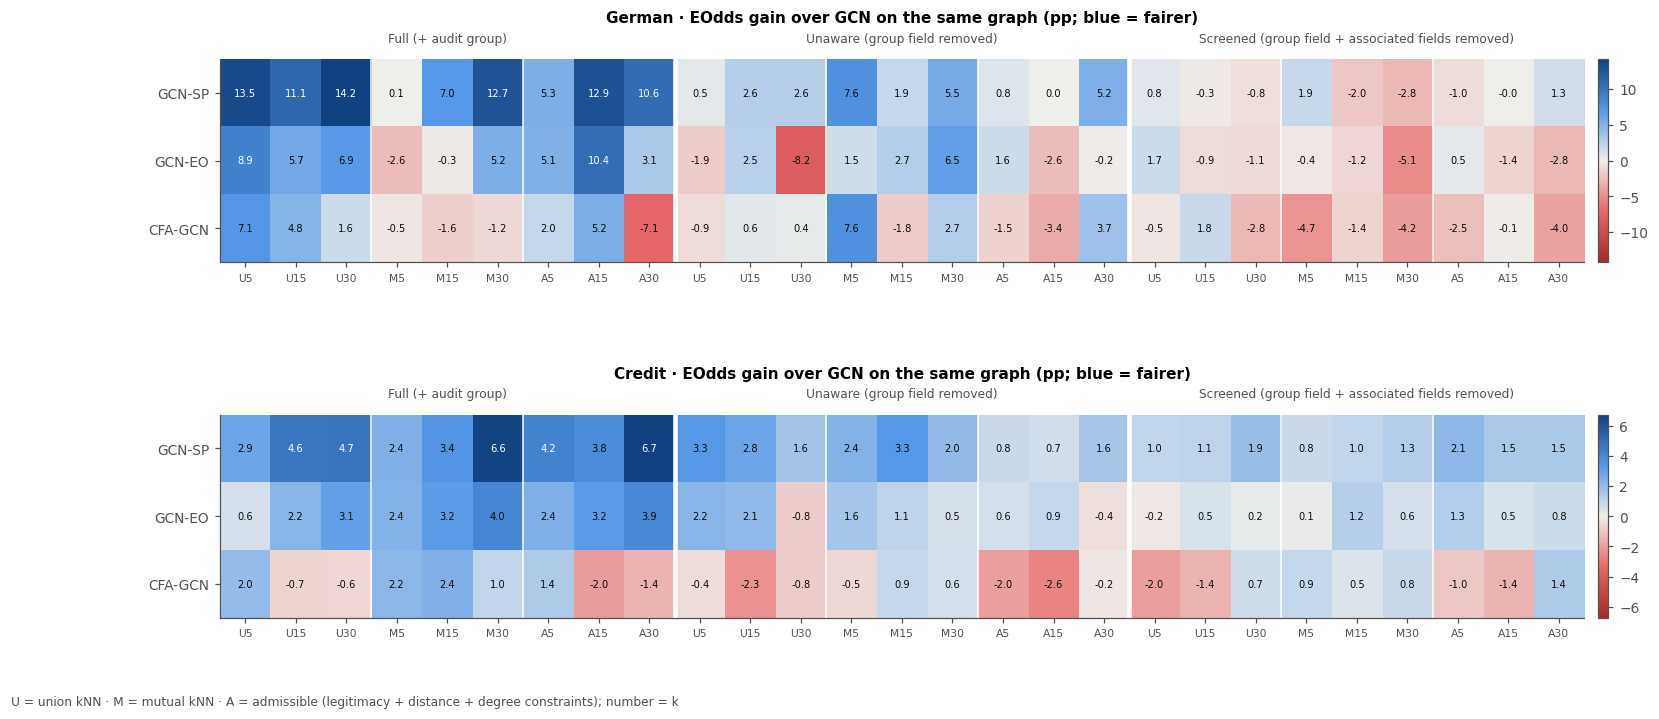

[35.1 min] saved Fig01_RQ1_gain_heatmap


In [10]:
def paired_gain(df, keys, col="eodds", base="GCN", methods=FAIR):
    pv = df.pivot_table(index=keys + ["seed"], columns="method", values=col)
    rows = []
    for m in methods:
        diff = (pv[base] - pv[m]).groupby(level=keys).agg(list)
        for key, vals in diff.items():
            mean, half = ci(vals); key = key if isinstance(key, tuple) else (key,)
            rows.append(dict(zip(keys, key), method=m, gain=mean, half=half, lo=mean - np.nan_to_num(half),
                             hi=mean + np.nan_to_num(half), n=len(vals), values=vals))
    return pd.DataFrame(rows)

RKEYS = ["dataset", "space", "family", "k"]
GAINS = paired_gain(RUNS, RKEYS)
recipes = [(sp, fam, k) for sp in CFG["spaces"] for fam in CFG["families"] for k in CFG["k_grid"]]
nk, nf = len(CFG["k_grid"]), len(CFG["families"])
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(max(9, 0.5 * len(recipes) + 3), 2.9 * len(DATASETS) + 0.8), squeeze=False,
                         gridspec_kw=dict(hspace=0.75))
for ax, ds in zip(axes[:, 0], DATASETS):
    g = GAINS[GAINS.dataset == ds].set_index(["method", "space", "family", "k"])["gain"]
    M = np.array([[g.get((m, sp, fam, k), np.nan) for sp, fam, k in recipes] for m in FAIR])
    lim = np.nanmax(np.abs(M)) or 1
    im = ax.imshow(M, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
    for r_ in range(M.shape[0]):
        for c_ in range(M.shape[1]):
            ax.text(c_, r_, f"{M[r_, c_]:.1f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(M[r_, c_]) > 0.6 * lim else INK)
    ax.set_xticks(range(len(recipes)), [f"{fam[0].upper()}{k}" for _, fam, k in recipes], fontsize=7)
    ax.set_yticks(range(len(FAIR)), FAIR); ax.grid(False)
    for b in range(1, len(recipes)):
        if b % nk == 0:
            ax.axvline(b - 0.5, color="white", lw=3 if b % (nk * nf) == 0 else 1)
    for b, sp in enumerate(CFG["spaces"]):
        ax.text((b + 0.5) * nk * nf - 0.5, -0.75, SPACE_LABEL[sp], ha="center", fontsize=8, color=INK2)
    ax.set_title(f"{ds} · EOdds gain over GCN on the same graph (pp; blue = fairer)", pad=24)
    fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
fig.text(0.01, -0.01, "U = union kNN · M = mutual kNN · A = admissible (legitimacy + distance + degree constraints); number = k",
         fontsize=8, color=INK2)
save_fig(fig, "Fig01_RQ1_gain_heatmap", "Paired EOdds gain of each fair method over GCN for every graph recipe")

### Cell 11 · Figure 2: specification curve of fairness gains (RQ1)
**What it does:** each point is one specification (recipe × fair method), sorted by its paired EOdds gain over GCN, with a 95% interval over splits. The indicator panel shows which choices define each specification. The title reports the share of specifications with a descriptive intervals entirely above and below zero, which answers *how general* a claimed improvement is.
**Main step:** M8 paired analysis, **Figure 2 (RQ1)**.

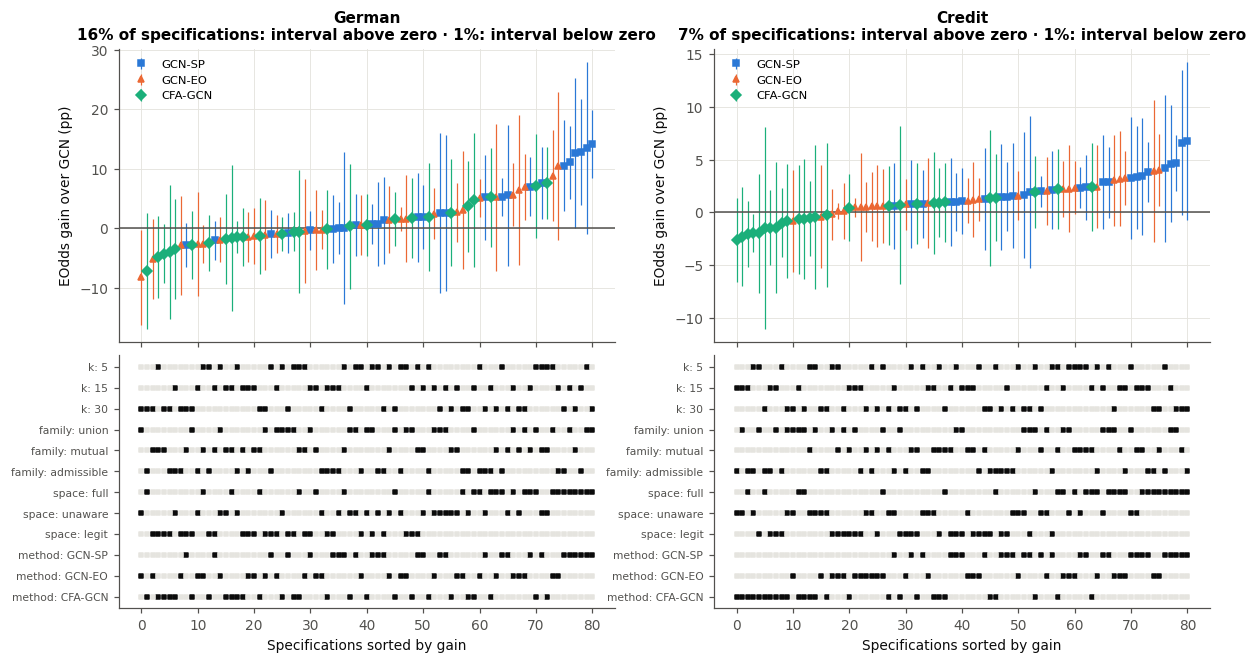

[35.2 min] saved Fig02_RQ1_specification_curve


In [11]:
ind_rows = ([("k", k) for k in CFG["k_grid"]] + [("family", f) for f in CFG["families"]]
            + [("space", s) for s in CFG["spaces"]] + [("method", m) for m in FAIR])
fig, axes = plt.subplots(2, len(DATASETS), figsize=(6.4 * len(DATASETS), 6.6),
                         gridspec_kw=dict(height_ratios=[2.2, 1.9], hspace=0.05), sharex="col", squeeze=False)
for c, ds in enumerate(DATASETS):
    sp = GAINS[GAINS.dataset == ds].sort_values("gain").reset_index(drop=True); x = np.arange(len(sp))
    ax = axes[0, c]
    for m in FAIR:
        sub = sp[sp.method == m]
        ax.errorbar(sub.index, sub.gain, yerr=sub.half.fillna(0), fmt=METHOD_MARKER[m], color=METHOD_COLOR[m],
                    ms=4.5, elinewidth=0.8, capsize=0, label=m)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_title(f"{ds}\n{(sp.lo > 0).mean():.0%} of specifications: interval above zero · {(sp.hi < 0).mean():.0%}: interval below zero")
    ax.set_ylabel("EOdds gain over GCN (pp)"); ax.legend(loc="upper left", fontsize=7.5)
    ax2 = axes[1, c]; ax2.grid(False)
    for r_, (f, v) in enumerate(ind_rows):
        on = (sp[f] == v).to_numpy()
        ax2.scatter(x[on], np.full(on.sum(), r_), s=7, marker="s", color=INK)
        ax2.scatter(x[~on], np.full((~on).sum(), r_), s=7, marker="s", color=GRID)
    ax2.set_yticks(range(len(ind_rows)), [f"{f}: {v}" for f, v in ind_rows], fontsize=7); ax2.invert_yaxis()
    ax2.set_xlabel("Specifications sorted by gain")
save_fig(fig, "Fig02_RQ1_specification_curve", "Specification curve of EOdds gains over GCN across the construction multiverse")

### Cell 12 · Table 2: construction envelope, rank stability and variance decomposition (RQ1)
**What it does:**
- **Panel A (per dataset × fair method):**
  - the mean gain and the range of recipe-level mean gains (minimum to maximum);
  - the number of recipes with a negative mean gain, and with descriptive intervals entirely above or below zero;
  - **splits containing a sign reversal** across recipes;
  - the share of recipes in which the method beats class-balanced logistic regression and validation-selected HGB on balanced accuracy (the utility-advantage part of RQ1).
- **Panel B (per dataset):**
  - **Kendall's W**: concordance of the seven non-trivial models' EOdds rankings across recipes;
  - marginal **η²**: the share of run-level EOdds and balanced-accuracy variance explained by method versus the construction factors (space, family, *k*) and the split.

**Main step:** M8 synthesis, **Table 2 (RQ1)**.

In [12]:
def kendall_w(R):
    R = np.asarray(R, dtype=float)
    m, n = R.shape; S = R.sum(0)
    ties = sum(sum(t ** 3 - t for t in np.unique(r, return_counts=True)[1]) for r in R)
    denominator = m ** 2 * (n ** 3 - n) - m * ties
    return 12 * ((S - S.mean()) ** 2).sum() / denominator if denominator > 0 else np.nan

lr_bal = TABR[(TABR.method == "LogReg") & (TABR.node == "blind")].set_index(["dataset", "seed"])["bal_acc"]
hgb_bal = TABR[(TABR.method == "HGB") & (TABR.node == "blind")].set_index(["dataset", "seed"])["bal_acc"]
panelA = []
for ds in DATASETS:
    for m in FAIR:
        g = GAINS[(GAINS.dataset == ds) & (GAINS.method == m)]
        pv = RUNS[(RUNS.dataset == ds)].pivot_table(index=["space", "family", "k", "seed"], columns="method", values="eodds")
        d = (pv["GCN"] - pv[m]).unstack("seed")
        rev = int(((d > 0).any(axis=0) & (d < 0).any(axis=0)).sum())
        rm = RUNS[(RUNS.dataset == ds) & (RUNS.method == m)].copy()
        rm["beats_lr"] = rm.bal_acc.values > lr_bal.loc[list(zip(rm.dataset, rm.seed))].values
        rm["beats_hgb"] = rm.bal_acc.values > hgb_bal.loc[list(zip(rm.dataset, rm.seed))].values
        panelA.append(dict(dataset=ds, method=m, mean_gain=g.gain.mean(), min_recipe_gain=g.gain.min(),
                           max_recipe_gain=g.gain.max(), recipes=len(g), recipes_negative_mean=int((g.gain < 0).sum()),
                           recipes_interval_above_zero=int((g.lo > 0).sum()), recipes_interval_below_zero=int((g.hi < 0).sum()),
                           splits_with_sign_reversal=f"{rev}/{len(CFG['seeds'])}",
                           share_runs_bal_acc_above_logreg=rm.beats_lr.mean(),
                           share_runs_bal_acc_above_hgb=rm.beats_hgb.mean()))
T2A = pd.DataFrame(panelA).round(3)
panelB = []
models6 = ["LogReg", "MLP", "HGB"] + GNN
tabm = TABR[TABR.node == "blind"].groupby(["dataset", "method"])["eodds"].mean()
for ds in DATASETS:
    d = RUNS[RUNS.dataset == ds]
    rk = d.groupby(["space", "family", "k", "method"])["eodds"].mean().unstack("method")
    for m in ["LogReg", "MLP", "HGB"]:
        rk[m] = tabm.loc[(ds, m)]
    W = kendall_w(rk[models6].rank(axis=1).to_numpy())
    for col in ["eodds", "bal_acc"]:
        sst = ((d[col] - d[col].mean()) ** 2).sum(); r_ = dict(dataset=ds, outcome=col, kendall_W_eodds_ranks=W)
        for f in ["method", "space", "family", "k", "seed"]:
            r_[f"eta2_{f}"] = d.groupby(f)[col].apply(lambda v: len(v) * (v.mean() - d[col].mean()) ** 2).sum() / sst
        r_["eta2_construction"] = r_["eta2_space"] + r_["eta2_family"] + r_["eta2_k"]
        r_["eta2_interactions_residual"] = 1 - sum(r_[f"eta2_{f}"] for f in ["method", "space", "family", "k", "seed"])
        panelB.append(r_)
T2B = pd.DataFrame(panelB).round(3)
save_table(T2A, "Table02A_RQ1_construction_envelope", "Construction envelope of EOdds gains, sign reversals and utility vs logistic regression")
save_table(T2B, "Table02B_RQ1_rank_stability_variance", "Kendall's W of model rankings and variance decomposition (method vs construction)")

**Table02A_RQ1_construction_envelope.** Construction envelope of EOdds gains, sign reversals and utility vs logistic regression

,dataset,method,mean_gain,min_recipe_gain,max_recipe_gain,recipes,recipes_negative_mean,recipes_interval_above_zero,recipes_interval_below_zero,splits_with_sign_reversal,share_runs_bal_acc_above_logreg,share_runs_bal_acc_above_hgb,group_definition
0,German,GCN-SP,4.110,-2.810,14.190,27,6,8,0,5/5,0.148,0.341,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
1,German,GCN-EO,1.244,-8.166,10.450,27,13,4,1,5/5,0.222,0.430,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
2,German,CFA-GCN,-0.037,-7.131,7.643,27,16,1,0,5/5,0.200,0.430,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
3,Credit,GCN-SP,2.594,0.659,6.730,27,0,4,0,5/5,0.267,0.215,"Primary audit: S=1 for documented SEX=2, S=0 f..."
4,Credit,GCN-EO,1.404,-0.795,4.037,27,3,2,0,5/5,0.311,0.267,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,CFA-GCN,-0.170,-2.623,2.377,27,15,0,1,5/5,0.385,0.326,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[35.2 min] saved Table02A_RQ1_construction_envelope


**Table02B_RQ1_rank_stability_variance.** Kendall's W of model rankings and variance decomposition (method vs construction)

,dataset,outcome,kendall_W_eodds_ranks,eta2_method,eta2_space,eta2_family,eta2_k,eta2_seed,eta2_construction,eta2_interactions_residual,group_definition
0,German,eodds,0.334,0.042,0.203,0.008,0.015,0.216,0.226,0.516,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
1,German,bal_acc,0.334,0.060,0.016,0.044,0.078,0.207,0.138,0.594,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
2,Credit,eodds,0.738,0.085,0.035,0.007,0.023,0.414,0.065,0.436,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,bal_acc,0.738,0.078,0.019,0.154,0.130,0.141,0.304,0.478,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[35.2 min] saved Table02B_RQ1_rank_stability_variance


## RQ2 · Recoverable audit-group information

### Cell 13 · Table 3: associated-field screening (RQ2)
**What it does:** for every original field, reports its mean training-only CV AUC and NMI for the dataset-specific audit group across the five splits, and how often it was among the top-3 *associated* fields removed in the *legit* space. Because the ranking is redone inside every split, no outer validation/test record influences which fields are removed.
**Main step:** M4 output, **Table 3 (RQ2)**.

In [13]:
T3 = (ASSOC.groupby(["dataset", "field"]).agg(mean_auc=("auc", "mean"), sd_auc=("auc", "std"), mean_nmi=("nmi", "mean"),
                                               mean_rank=("rank", "mean"), times_removed=("removed", "sum"))
          .reset_index().sort_values(["dataset", "mean_rank"]).round(4))
save_table(T3, "Table03_RQ2_associated_field_screening",
           "Training-only association with the dataset-specific audit group (5 splits); top-3 fields are screened",
           show=T3.groupby("dataset").head(8))

**Table03_RQ2_associated_field_screening.** Training-only association with the dataset-specific audit group (5 splits); top-3 fields are screened

,dataset,field,mean_auc,sd_auc,mean_nmi,mean_rank,times_removed
11,Credit,PAY_2,0.5436,0.0098,0.0055,2.2,3
0,Credit,AGE,0.5449,0.0056,0.0027,2.6,3
12,Credit,PAY_3,0.5407,0.0072,0.0049,3.2,4
13,Credit,PAY_4,0.5360,0.0113,0.0049,4.6,3
1,Credit,BILL_AMT1,0.5357,0.0056,0.0017,5.2,1
2,Credit,BILL_AMT2,0.5348,0.0060,0.0020,5.2,1
14,Credit,PAY_5,0.5303,0.0095,0.0034,7.6,0
3,Credit,BILL_AMT3,0.5282,0.0037,0.0011,8.8,0
22,German,age,0.6284,0.0088,0.0297,1.2,5
27,German,employment_since,0.6229,0.0304,0.0278,2.0,5


[35.2 min] saved Table03_RQ2_associated_field_screening


### Cell 14 · Figure 3: excess sensitive homophily by attribute space and family (RQ2)
**What it does:** plots the share of same-group edges minus the random-mixing expectation against *k*. Colour = attribute space, line style = graph family. The *full* space includes the audit-group indicator. The unaware/screened contrast describes sensitivity to field removal; it does not identify a causal contribution.
**Main step:** M5 + M9 diagnostic, **Figure 3 (RQ2)**.

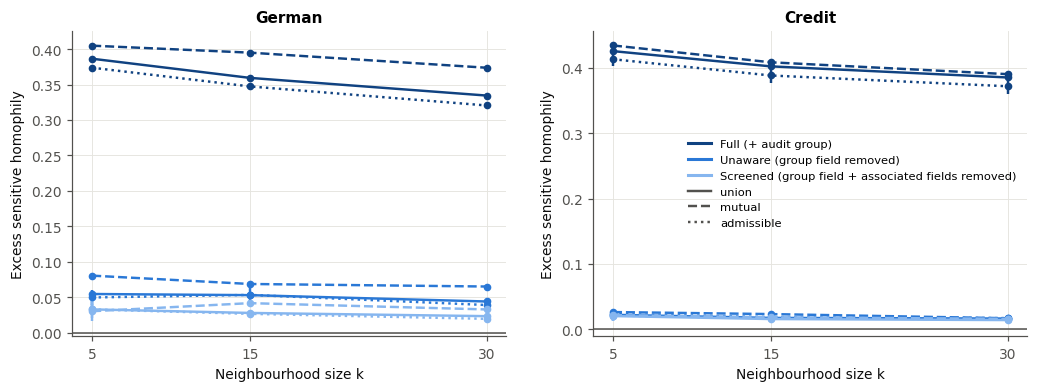

[35.2 min] saved Fig03_RQ2_excess_sensitive_homophily


In [14]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.6 * len(DATASETS), 3.6), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    g = G3[G3.dataset == ds].groupby(["space", "family", "k"])["excess_h_sens"].agg(list)
    for sp in CFG["spaces"]:
        for fam in CFG["families"]:
            vals = [ci(g[(sp, fam, k)]) for k in CFG["k_grid"]]
            ax.errorbar(CFG["k_grid"], [v[0] for v in vals], yerr=np.nan_to_num([v[1] for v in vals]), color=SPACE_COLOR[sp],
                        ls=FAMILY_STYLE[fam], marker="o", ms=4, capsize=0, lw=1.6)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(CFG["k_grid"])
    ax.set_xlabel("Neighbourhood size k"); ax.set_ylabel("Excess sensitive homophily"); ax.set_title(ds)
handles = ([Line2D([], [], color=SPACE_COLOR[s], lw=2, label=SPACE_LABEL[s]) for s in CFG["spaces"]]
           + [Line2D([], [], color=INK2, ls=FAMILY_STYLE[f], lw=1.6, label=f) for f in CFG["families"]])
axes[0, -1].legend(handles=handles, fontsize=7.5, loc="best")
save_fig(fig, "Fig03_RQ2_excess_sensitive_homophily", "Excess sensitive homophily by attribute space, family and k")

### Cell 15 · Figure 4: sensitive information re-entering through propagation (RQ2)
**What it does:** shows the held-out AUC of a training-fitted linear probe for the dataset-specific audit group, computed on the fixed node features after 0, 1 and 2 propagation hops over each space's union graph (solid) and admissible graph (dotted) at *k* = 15. Hop 0 is identical because the same group-field-excluded inputs are used. Differences after propagation measure recoverable information from combined features and graph structure; they do not isolate a topology-only or causal channel. German targets are G, not verified sex.
**Main step:** M9, **Figure 4 (RQ2)**.

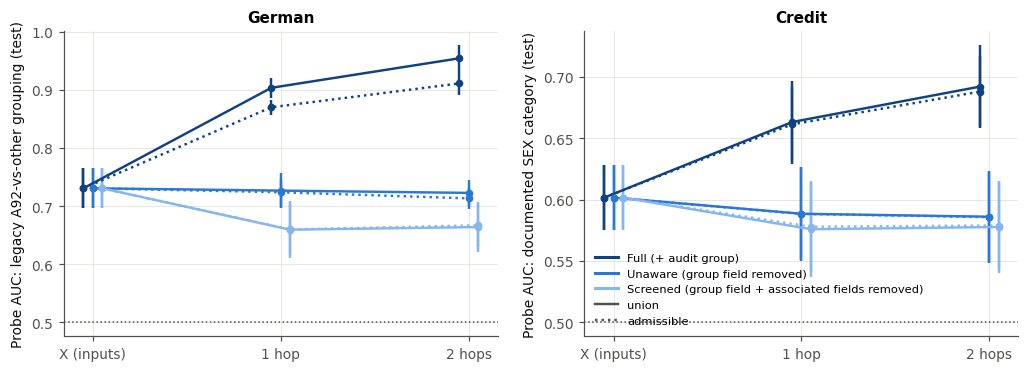

[35.2 min] saved Fig04_RQ2_sensitive_probe_propagation


In [15]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.6 * len(DATASETS), 3.6), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    for j, sp in enumerate(CFG["spaces"]):
        for fam in ("union", "admissible"):
            gg = PROBES[(PROBES.dataset == ds) & (PROBES.space == sp) & (PROBES.family == fam)].groupby("hop")["auc"].agg(list)
            vals = [ci(v) for v in gg]
            ax.errorbar(np.array(gg.index) + (j - 1) * 0.05, [v[0] for v in vals], yerr=np.nan_to_num([v[1] for v in vals]),
                        color=SPACE_COLOR[sp], ls=FAMILY_STYLE[fam], marker="o", ms=4, capsize=0, lw=1.6)
    ax.axhline(0.5, color=INK2, ls=":", lw=1)
    ax.set_xticks([0, 1, 2], ["X (inputs)", "1 hop", "2 hops"]); ax.set_ylabel(f"Probe AUC: {GROUP_LABEL[ds]} (test)"); ax.set_title(ds)
handles = ([Line2D([], [], color=SPACE_COLOR[s], lw=2, label=SPACE_LABEL[s]) for s in CFG["spaces"]]
           + [Line2D([], [], color=INK2, ls=FAMILY_STYLE[f], lw=1.6, label=f) for f in ("union", "admissible")])
axes[0, -1].legend(handles=handles, fontsize=7.5, loc="best")
save_fig(fig, "Fig04_RQ2_sensitive_probe_propagation", "Recoverability of the dataset-specific audit group from propagated node features")

### Cell 16 · Table 4: crossed feature × topology ablation (RQ2)
**What it does:** at union *k* = 15, crosses two choices:
- **node features:** *blind* (group-defining field excluded) or *pruned* (group-defining and associated fields removed);
- **topology features:** the same two options, applied to the graph distances.

For every GNN it reports balanced accuracy, EOdds and ΔSP (mean ± 95% CI over splits), with MLPs on blind and on pruned features as graph-free references. The table separates whether disparity travels through the **features**, the **graph**, or both.
**Main step:** M9 crossed ablation, **Table 4 (RQ2)**.

In [16]:
base = RUNS[(RUNS.family == "union") & (RUNS.k == CFG["ref_k"]) & RUNS.space.isin(["unaware", "legit"])].copy()
base["node"] = "blind"; base["topology"] = base.space.map({"unaware": "blind", "legit": "pruned"})
mlp = TABR[TABR.method.isin(["MLP", "LogReg"])].assign(topology="none (tabular)")
AB = pd.concat([base, ABL, mlp], ignore_index=True)
T4 = (AB.groupby(["dataset", "node", "topology", "method"])
        .agg(bal_acc=("bal_acc", fmt), eodds=("eodds", fmt), dsp=("dsp", fmt), n=("seed", "size")).reset_index())
order = {m: i for i, m in enumerate(["LogReg", "MLP"] + GNN)}
T4 = T4.sort_values(["dataset", "method", "node", "topology"], key=lambda c: c.map(order) if c.name == "method" else c)
save_table(T4, "Table04_RQ2_crossed_feature_topology_ablation",
           "Crossed removal of associated fields from node features and/or graph distances (union k=15; mean ± 95% CI)")

**Table04_RQ2_crossed_feature_topology_ablation.** Crossed removal of associated fields from node features and/or graph distances (union k=15; mean ± 95% CI)

,dataset,node,topology,method,bal_acc,eodds,dsp,n,group_definition
4,Credit,blind,none (tabular),LogReg,69.00 ± 1.32,6.80 ± 5.17,6.34 ± 4.30,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
14,Credit,pruned,none (tabular),LogReg,69.22 ± 1.34,7.76 ± 2.62,6.09 ± 4.12,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,blind,none (tabular),MLP,70.79 ± 0.75,7.93 ± 4.73,6.77 ± 3.87,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
15,Credit,pruned,none (tabular),MLP,69.85 ± 1.44,7.82 ± 3.86,6.50 ± 3.21,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
1,Credit,blind,blind,GCN,67.97 ± 1.20,9.53 ± 4.95,7.11 ± 1.98,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
7,Credit,blind,pruned,GCN,68.36 ± 1.18,8.21 ± 4.69,6.60 ± 4.37,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
11,Credit,pruned,blind,GCN,68.48 ± 1.24,10.04 ± 3.83,6.93 ± 2.54,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
17,Credit,pruned,pruned,GCN,68.23 ± 1.27,9.81 ± 3.58,6.49 ± 2.87,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,blind,blind,GCN-SP,66.77 ± 2.33,6.69 ± 3.69,4.35 ± 4.14,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
9,Credit,blind,pruned,GCN-SP,67.21 ± 1.44,7.15 ± 4.25,3.79 ± 3.88,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[35.2 min] saved Table04_RQ2_crossed_feature_topology_ablation


## RQ3 · Edge-admissibility audit

### Cell 17 · Figure 5: where inadmissible edges come from (RQ3)
**What it does:** plots the empirical CDF of the normalised screened-space neighbour rank r_ij (log scale) for same-group and cross-group edges of the union *k* = 15 graphs in the *full* and *unaware* spaces (primary split). Edges right of κ=2 fail the declared screened-rank rule. Same/cross-group differences describe this rule, not causal attribution or evidence of verified demographic membership in German.
**Main step:** M6 diagnostic, **Figure 5 (RQ3)**.

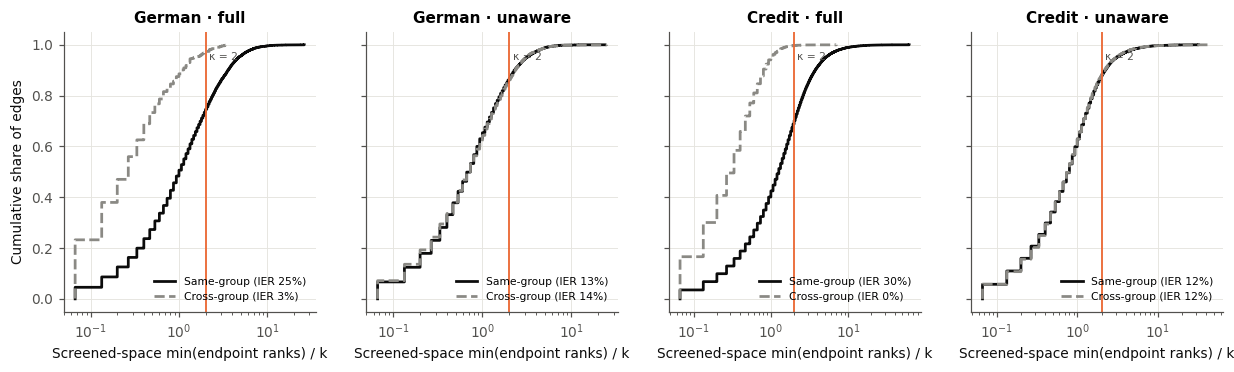

[35.2 min] saved Fig05_RQ3_legitimacy_rank_ecdf


In [17]:
pairs = [(d, s) for d in DATASETS for s in ["full", "unaware"]]
fig, axes = plt.subplots(1, len(pairs), figsize=(3.4 * len(pairs), 3.3), sharey=True, squeeze=False)
for ax, (ds, sp) in zip(axes[0], pairs):
    e = EDGES[(EDGES.dataset == ds) & (EDGES.space == sp)]
    for same, ls, col, lab in [(True, "-", INK, "Same-group"), (False, "--", "#8a8984", "Cross-group")]:
        r = np.sort(e.r[e.same == same].to_numpy())
        if len(r):
            ax.step(r, np.arange(1, len(r) + 1) / len(r), where="post", color=col, ls=ls, lw=1.8,
                    label=f"{lab} (IER {(r > CFG['kappa']).mean():.0%})")
    ax.axvline(CFG["kappa"], color=METHOD_COLOR["GCN-EO"], lw=1.2)
    ax.text(CFG["kappa"] * 1.1, 0.97, "κ = 2", fontsize=7, color=INK2, va="top")
    ax.set_xscale("log"); ax.set_xlabel("Screened-space min(endpoint ranks) / k"); ax.set_title(f"{ds} · {sp}"); ax.legend(loc="lower right", fontsize=7)
axes[0, 0].set_ylabel("Cumulative share of edges")
save_fig(fig, "Fig05_RQ3_legitimacy_rank_ecdf", "Screened-space rank distribution of same- vs cross-group edges (union k=15)")

### Cell 18 · Table 5: admissibility audit card (RQ3)
**What it does:** for every union graph (space × *k*, mean over splits), reports:
- the audit statistics: IER overall and for same- and cross-group edges, distance-ceiling and degree-cap violations, and group degree ratio;
- what the admissible filter changes: the share of edges retained, the isolated share, and excess sensitive homophily of the union, admissible and density-matched random graphs.

This is the artefact an auditor would attach to a fair-GNN claim.
**Main step:** M6 output, **Table 5 (RQ3)**.

In [18]:
u = GRAPHS[GRAPHS.family == "union"].groupby(["dataset", "space", "k"])[
    ["edges", "IER", "IER_same", "IER_cross", "distance_violation", "degree_violation", "degree_group_ratio", "excess_h_sens"]].mean()
a = GRAPHS[GRAPHS.family == "admissible"].groupby(["dataset", "space", "k"])[["edges", "isolated", "excess_h_sens"]].mean()
r = GRAPHS[GRAPHS.family == "random_matched"].groupby(["dataset", "space", "k"])[["excess_h_sens"]].mean()
T5 = u.join(a, rsuffix="_admissible").join(r, rsuffix="_random_matched").reset_index()
T5["retained_share"] = T5.edges_admissible / T5.edges
T5 = T5.rename(columns={"excess_h_sens": "excess_h_union", "excess_h_sens_admissible": "excess_h_admissible",
                        "excess_h_sens_random_matched": "excess_h_random_matched", "isolated": "isolated_admissible"}).round(3)
save_table(T5, "Table05_RQ3_admissibility_audit_card", "Edge-admissibility audit card for union kNN graphs (mean over 5 splits)")

**Table05_RQ3_admissibility_audit_card.** Edge-admissibility audit card for union kNN graphs (mean over 5 splits)

,dataset,space,k,edges,IER,IER_same,IER_cross,distance_violation,degree_violation,degree_group_ratio,excess_h_union,edges_admissible,isolated_admissible,excess_h_admissible,excess_h_random_matched,retained_share,group_definition
0,Credit,full,5,18652.0,0.283,0.298,0.014,0.033,0.109,1.027,0.426,12534.6,0.024,0.413,0.426,0.672,"Primary audit: S=1 for documented SEX=2, S=0 f..."
1,Credit,full,15,55450.4,0.217,0.234,0.008,0.031,0.101,1.039,0.403,41152.0,0.004,0.389,0.403,0.742,"Primary audit: S=1 for documented SEX=2, S=0 f..."
2,Credit,full,30,111051.8,0.180,0.198,0.008,0.030,0.109,1.050,0.386,85980.4,0.002,0.372,0.386,0.774,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,legit,5,18450.4,0.000,0.000,0.000,0.033,0.095,1.009,0.020,16862.6,0.011,0.021,NaN,0.914,"Primary audit: S=1 for documented SEX=2, S=0 f..."
4,Credit,legit,15,54854.6,0.000,0.000,0.000,0.031,0.088,1.013,0.016,51320.8,0.004,0.017,NaN,0.936,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,legit,30,109820.6,0.000,0.000,0.000,0.030,0.088,1.018,0.014,103028.8,0.002,0.015,NaN,0.938,"Primary audit: S=1 for documented SEX=2, S=0 f..."
6,Credit,unaware,5,18630.6,0.128,0.128,0.128,0.033,0.107,1.001,0.022,14930.2,0.015,0.023,0.022,0.801,"Primary audit: S=1 for documented SEX=2, S=0 f..."
7,Credit,unaware,15,55488.0,0.085,0.085,0.084,0.032,0.099,1.011,0.017,47244.0,0.004,0.019,0.017,0.851,"Primary audit: S=1 for documented SEX=2, S=0 f..."
8,Credit,unaware,30,110939.0,0.061,0.063,0.059,0.030,0.100,1.015,0.016,96863.6,0.002,0.017,0.016,0.873,"Primary audit: S=1 for documented SEX=2, S=0 f..."
9,German,full,5,3734.0,0.341,0.353,0.052,0.023,0.128,1.029,0.387,2315.4,0.014,0.374,0.387,0.620,"Sensitivity analysis: G=1 for Attribute9=A92, ..."


[35.2 min] saved Table05_RQ3_admissibility_audit_card


### Cell 19 · Figure 6: retraining on admissible vs matched-random graphs (RQ3)
**What it does:** for every GNN, plots the paired change in test EOdds when the union graph is replaced by
- its **admissible** subgraph (filled markers), or
- a **random subgraph with the same edge count** (hollow markers).

Results are shown for the *full* and *unaware* spaces, with descriptive 95% t-intervals over split-level means (k is averaged within each split). Negative values mean a smaller gap. If the admissible effect differs from the random effect, the constraint does something beyond removing edges.
**Main step:** M10 retrained intervention, **Figure 6 (RQ3)**.

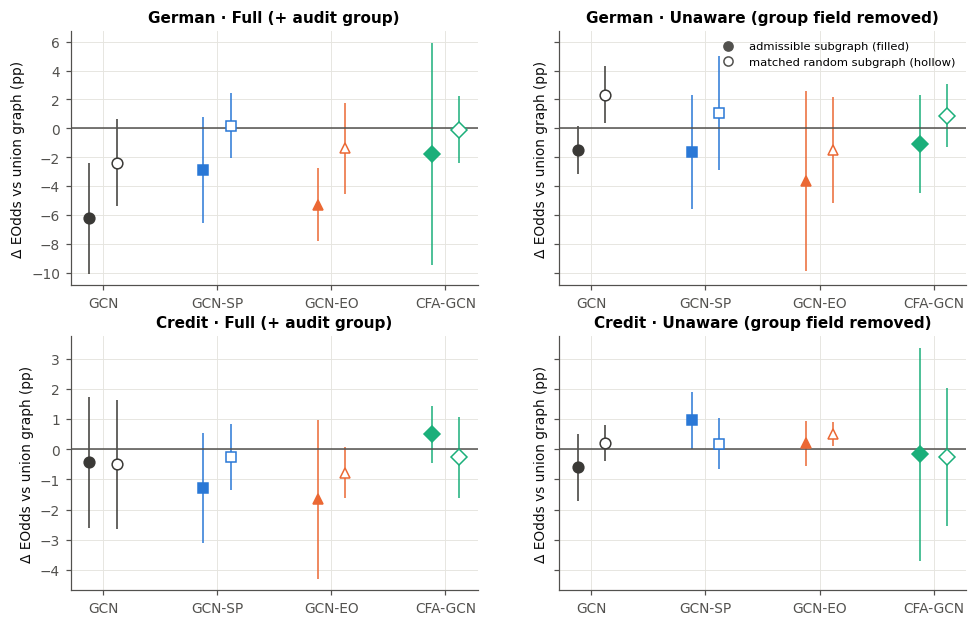

[35.3 min] saved Fig06_RQ3_admissible_vs_random_retrained


In [19]:
key = ["dataset", "seed", "space", "k", "method"]
U_ = RUNS[RUNS.family == "union"].set_index(key)
dA = (RUNS[RUNS.family == "admissible"].set_index(key)[["eodds", "bal_acc"]] - U_[["eodds", "bal_acc"]]).dropna().reset_index()
RANDOM_MEAN = RANDOM.groupby(key)[["eodds", "bal_acc"]].mean()
dR = (RANDOM_MEAN - U_[["eodds", "bal_acc"]]).dropna().reset_index()
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(10.5, 3.3 * len(DATASETS)), sharey="row", squeeze=False)
for r_, ds in enumerate(DATASETS):
    for c_, sp in enumerate(["full", "unaware"]):
        ax = axes[r_, c_]
        for x, m in enumerate(GNN):
            for dd, off, filled in [(dA, -0.12, True), (dR, 0.12, False)]:
                # Average over k within each split before describing between-split variation.
                v = dd[(dd.dataset == ds) & (dd.space == sp) & (dd.method == m)].groupby("seed")["eodds"].mean()
                mean, half = ci(v)
                ax.errorbar(x + off, mean, yerr=np.nan_to_num(half), fmt=METHOD_MARKER[m], ms=7, capsize=0, elinewidth=1,
                            color=METHOD_COLOR[m], mfc=METHOD_COLOR[m] if filled else "white")
        ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(len(GNN)), GNN)
        ax.set_title(f"{ds} · {SPACE_LABEL[sp]}"); ax.set_ylabel("Δ EOdds vs union graph (pp)")
handles = [Line2D([], [], color=INK2, marker="o", ls="", label="admissible subgraph (filled)"),
           Line2D([], [], color=INK2, marker="o", mfc="white", ls="", label="matched random subgraph (hollow)")]
axes[0, 1].legend(handles=handles, fontsize=7.5, loc="best")
save_fig(fig, "Fig06_RQ3_admissible_vs_random_retrained", "Change in EOdds after retraining; average over k within each split, descriptive split intervals")

### Cell 20 · Table 6: fixed-model edge interventions (RQ3)
**What it does:** holds every model trained on the union *k* = 15 graph **fixed** and re-predicts after removing edges that violate (a) legitimacy only, (b) the distance ceiling only, (c) the degree cap only, or (d) all constraints. Each of (a)–(d) has its own edge-count-matched random control (three draws; two in quick mode). It reports the retained share, changes in EOdds, ΔSP and balanced accuracy, and prediction flips. S5 reports direct paired audit-minus-random differences. Draws are averaged within split before descriptive split intervals. This is a fixed-parameter sensitivity analysis, not a causal fairness test; random controls do not preserve the full degree sequence.
**Main step:** M10 fixed-model intervention, **Table 6 (RQ3)**.

In [20]:
iv = INTERV.copy(); iv["intervention"] = iv.intervention.str.replace(r"_\d+$", "", regex=True)
iv = iv.groupby(["dataset", "seed", "space", "method", "intervention"])[["retained", "d_eodds", "d_dsp", "d_bal_acc", "flips"]].mean().reset_index()
T6 = (iv.groupby(["dataset", "space", "method", "intervention"])
        .agg(retained=("retained", lambda v: round(v.mean(), 3)), d_eodds=("d_eodds", fmt), d_dsp=("d_dsp", fmt),
             d_bal_acc=("d_bal_acc", fmt), flips_pct=("flips", fmt)).reset_index())
iv_order = {k: i for i, k in enumerate(["legitimacy", "random_legitimacy", "distance", "random_distance",
                                     "degree", "random_degree", "all_constraints", "random_all_constraints"])}
T6 = T6.sort_values(["dataset", "space", "method", "intervention"], key=lambda c: c.map(iv_order) if c.name == "intervention" else c)
save_table(T6, "Table06_RQ3_fixed_model_edge_interventions",
           "Fixed trained models re-evaluated on constraint-filtered vs matched-random graphs (union k=15; mean ± 95% CI)",
           show=T6[T6.method.isin(["GCN", "GCN-EO"])])

**Table06_RQ3_fixed_model_edge_interventions.** Fixed trained models re-evaluated on constraint-filtered vs matched-random graphs (union k=15; mean ± 95% CI)

,dataset,space,method,intervention,retained,d_eodds,d_dsp,d_bal_acc,flips_pct
11,Credit,full,GCN,legitimacy,0.783,-0.52 ± 1.48,0.12 ± 0.86,-0.25 ± 0.42,2.60 ± 1.27
15,Credit,full,GCN,random_legitimacy,0.783,-0.60 ± 1.70,0.20 ± 0.49,-0.11 ± 0.21,2.01 ± 1.27
10,Credit,full,GCN,distance,0.969,-0.86 ± 1.43,-0.50 ± 0.46,0.09 ± 0.54,1.12 ± 0.31
14,Credit,full,GCN,random_distance,0.969,-0.02 ± 1.07,0.12 ± 0.40,0.02 ± 0.17,0.51 ± 0.18
9,Credit,full,GCN,degree,0.953,0.02 ± 0.33,0.08 ± 0.79,0.11 ± 0.39,0.70 ± 0.52
...,...,...,...,...,...,...,...,...,...
118,German,unaware,GCN-EO,random_distance,0.975,0.57 ± 1.40,0.23 ± 1.43,0.09 ± 0.64,1.30 ± 1.07
113,German,unaware,GCN-EO,degree,0.922,0.61 ± 3.60,-0.05 ± 0.80,0.86 ± 1.58,2.20 ± 0.71
117,German,unaware,GCN-EO,random_degree,0.922,0.09 ± 2.03,0.35 ± 1.46,-0.22 ± 0.68,1.87 ± 0.86
112,German,unaware,GCN-EO,all_constraints,0.790,2.13 ± 5.66,-1.01 ± 6.28,0.69 ± 1.98,4.70 ± 1.62


[35.3 min] saved Table06_RQ3_fixed_model_edge_interventions


## RQ4 · Validation-locked graph selection
### Cell 21 · Existing selector policies, retained (M11)
For each dataset, split and fair method, candidate spaces are `unaware` and `legit`. Metrics are on the 0-100 scale. Reference U*=maximum validation balanced accuracy among that method's eligible recipes; floor U*-tol, with tol=2 percentage points. Tabular models and other GNN methods do not define this reference.
- `utility_only`: sort validation BA descending, validation EOdds ascending, then space/family/k ascending.
- `fairness_only`: keep recipes meeting the floor; sort validation EOdds ascending, BA descending, then space/family/k ascending.
- `constraint_audit`: retain the admissible family within the floor. A space's `worst` score is its maximum validation EOdds over **all admissible k**, including k below the utility floor. Sort candidate rows by worst, EOdds, descending BA, k, space and family. If none meets the floor, automatically use all admissible candidates and flag the relaxation.
Exact floating-point score equality defines ties; no rounding tolerance is introduced. Final lexicographic keys resolve remaining ties explicitly. No-feasible-selection behaviour has **not** been substituted for automatic relaxation. Exported selections now include the reference, floor, actual validation shortfall and worst-case score.
Test columns are retrieved after the recipe is selected and do not affect the choice. This is a method-relative budget with flagged exceptions, not an unconditional common/hard utility guarantee. The cross-k objective also differs from the fairness-only objective, so their comparison does not isolate the audit-family restriction alone.

In [21]:
ELIG = RUNS[RUNS.space.isin(["unaware", "legit"])]
GCN_RUN = RUNS[RUNS.method == "GCN"].set_index(["dataset", "seed", "space", "family", "k"])

def select(tol):
    out = []
    for (ds, seed, m), el in ELIG[ELIG.method.isin(FAIR)].groupby(["dataset", "seed", "method"]):
        utility_reference = float(el.val_bal_acc.max()); utility_floor = utility_reference - tol
        near = el[el.val_bal_acc >= utility_floor]
        choice = {"utility_only": el.sort_values(["val_bal_acc", "val_eodds", "space", "family", "k"],
                                                 ascending=[False, True, True, True, True]).iloc[0],
                  "fairness_only": near.sort_values(["val_eodds", "val_bal_acc", "space", "family", "k"],
                                                    ascending=[True, False, True, True, True]).iloc[0]}
        adm = near[near.family == "admissible"]; relaxed = adm.empty
        if relaxed:
            adm = el[el.family == "admissible"]
        worst = el[el.family == "admissible"].groupby("space").val_eodds.max()
        adm = adm.assign(worst=adm.space.map(worst))
        choice["constraint_audit"] = adm.sort_values(["worst", "val_eodds", "val_bal_acc", "k", "space", "family"],
                                                     ascending=[True, True, False, True, True, True]).iloc[0]
        for sel, ch in choice.items():
            gcn = GCN_RUN.loc[(ds, seed, ch.space, ch.family, ch.k)]
            out.append(dict(dataset=ds, seed=seed, method=m, selector=sel, tol=tol, space=ch.space, family=ch.family, k=int(ch.k),
                            val_bal_acc=ch.val_bal_acc, val_eodds=ch.val_eodds, bal_acc=ch.bal_acc, eodds=ch.eodds,
                            gcn_eodds=gcn.eodds, gain_vs_gcn=gcn.eodds - ch.eodds,
                            floor_relaxed=bool(relaxed) if sel == "constraint_audit" else False,
                            utility_reference_val=utility_reference, utility_floor_val=utility_floor,
                            utility_shortfall_val=max(0.0, utility_floor - float(ch.val_bal_acc)),
                            worst_val_eodds=float(ch["worst"]) if sel == "constraint_audit" else np.nan))
    return pd.DataFrame(out)

SEL = select(CFG["utility_tol"]); SEL.to_csv(RAW_DIR / "selections.csv", index=False)

def controlled_selector_contrasts(eligible, tol):
    # Separate family restriction from the minimax objective on the same feasible set.
    # No automatic relaxation: abstentions are counted, never replaced by favourable
    # test outcomes. All three choices depend exclusively on validation.
    rows = []
    for (ds, seed, m), el in eligible[eligible.method.isin(FAIR)].groupby(["dataset", "seed", "method"]):
        floor = el.val_bal_acc.max() - tol
        near = el[el.val_bal_acc >= floor]; adm = near[near.family == "admissible"]
        rec = dict(dataset=ds, seed=seed, method=m, feasible=not adm.empty,
                   utility_floor_val=float(floor), admissible_candidates=len(adm))
        rec.update({f"{contrast}_d_{metric}": np.nan
                    for contrast in ["family_only", "minimax"] for metric in ["eodds", "bal_acc"]})
        if not adm.empty:
            order = ["val_eodds", "val_bal_acc", "space", "family", "k"]
            ascending = [True, False, True, True, True]
            free = near.sort_values(order, ascending=ascending).iloc[0]
            family = adm.sort_values(order, ascending=ascending).iloc[0]
            worst = el[el.family == "admissible"].groupby("space").val_eodds.max()
            minimax = adm.assign(worst=adm.space.map(worst)).sort_values(
                ["worst", "val_eodds", "val_bal_acc", "k", "space", "family"],
                ascending=[True, True, False, True, True, True]).iloc[0]
            for name, ch in [("fairness_only", free), ("admissible_only", family), ("constraint_audit", minimax)]:
                rec[f"{name}_recipe"] = f"{ch.space}/{ch.family}/k{ch.k}"
            for metric in ["eodds", "bal_acc"]:
                rec[f"family_only_d_{metric}"] = float(family[metric] - free[metric])
                rec[f"minimax_d_{metric}"] = float(minimax[metric] - family[metric])
        rows.append(rec)
    return pd.DataFrame(rows)

CONTROLLED = controlled_selector_contrasts(ELIG, CFG["utility_tol"])
CONTROLLED.to_csv(RAW_DIR / "selector_controlled_contrasts.csv", index=False)
display(SEL.groupby(["dataset", "selector", "family"]).size().unstack(fill_value=0))

family                    admissible  mutual  union
dataset selector                                   
Credit  constraint_audit          15       0      0
        fairness_only              3       6      6
        utility_only               2      12      1
German  constraint_audit          15       0      0
        fairness_only              2      10      3
        utility_only               2      13      0

### Cell 22 · Table 7: what each selector buys on held-out persons (RQ4)
**What it does:** compares the three selectors per dataset × fair method on **test** balanced accuracy, EOdds, and the paired EOdds gain over GCN on the same selected recipe (mean ± 95% CI over splits), and counts utility-floor relaxations and reports the maximum validation-floor shortfall. Logistic regression, MLP and HGB are included as graph-free references.
**Main step:** M11 evaluation, **Table 7 (RQ4)**.

In [22]:
T7 = (SEL.groupby(["dataset", "method", "selector"])
        .agg(bal_acc=("bal_acc", fmt), eodds=("eodds", fmt), gain_vs_gcn=("gain_vs_gcn", fmt),
             recipes=("family", lambda f: ", ".join(sorted(set(f)))), floor_relaxed=("floor_relaxed", "sum"),
             max_validation_floor_shortfall=("utility_shortfall_val", "max")).reset_index())
tabref = (TABR[(TABR.node == "blind") & TABR.method.isin(["LogReg", "MLP", "HGB"])].groupby(["dataset", "method"])
          .agg(bal_acc=("bal_acc", fmt), eodds=("eodds", fmt)).reset_index().assign(selector="graph-free reference"))
T7 = pd.concat([T7, tabref], ignore_index=True).sort_values(["dataset", "method"])
save_table(T7, "Table07_RQ4_validation_locked_selection",
           "Held-out balanced accuracy and EOdds of validation-locked selectors (mean ± 95% CI over 5 splits)")

**Table07_RQ4_validation_locked_selection.** Held-out balanced accuracy and EOdds of validation-locked selectors (mean ± 95% CI over 5 splits)

,dataset,method,selector,bal_acc,eodds,gain_vs_gcn,recipes,floor_relaxed,max_validation_floor_shortfall,group_definition
0,Credit,CFA-GCN,constraint_audit,68.21 ± 2.49,9.87 ± 6.06,-2.80 ± 4.01,admissible,1.0,3.467357,"Primary audit: S=1 for documented SEX=2, S=0 f..."
1,Credit,CFA-GCN,fairness_only,69.06 ± 1.18,8.69 ± 5.92,-1.90 ± 4.98,"mutual, union",0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
2,Credit,CFA-GCN,utility_only,69.66 ± 1.54,7.44 ± 2.92,0.96 ± 3.82,"admissible, mutual",0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,GCN-EO,constraint_audit,69.07 ± 1.52,8.13 ± 5.36,0.58 ± 1.07,admissible,0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
4,Credit,GCN-EO,fairness_only,68.85 ± 0.41,7.16 ± 3.39,2.44 ± 3.77,"mutual, union",0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,GCN-EO,utility_only,68.81 ± 1.08,6.73 ± 3.76,1.97 ± 3.35,"mutual, union",0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
6,Credit,GCN-SP,constraint_audit,67.48 ± 1.66,6.28 ± 3.29,0.27 ± 4.45,admissible,0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
7,Credit,GCN-SP,fairness_only,67.58 ± 1.54,7.87 ± 2.95,1.35 ± 6.38,"admissible, mutual, union",0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
8,Credit,GCN-SP,utility_only,68.74 ± 0.93,7.20 ± 3.82,0.67 ± 4.01,"admissible, mutual",0.0,0.000000,"Primary audit: S=1 for documented SEX=2, S=0 f..."
18,Credit,HGB,graph-free reference,69.27 ± 1.33,7.57 ± 3.89,NaN,NaN,NaN,NaN,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[35.3 min] saved Table07_RQ4_validation_locked_selection


### Cell 23 · Figure 7: does validation rank graph recipes the way test does? (RQ4)
**What it does:** a validation-locked selector can only work if validation metrics order the candidate recipes the way test metrics do. For every deployable recipe (*unaware* and *legit* spaces, all families and *k*) and fair method, it plots the validation value against the test value, for EOdds (top) and balanced accuracy (bottom). The dashed line is perfect agreement, and hollow amber circles mark the recipes picked by the constraint_audit selector. The panel text gives the **within-split Spearman rank correlation** between validation and test across recipes (method correlations averaged within each split; mean ± descriptive 95% t-interval over splits), which is the quantity that matters for selection.
**Main step:** M11 diagnostic, **Figure 7 (RQ4)**.

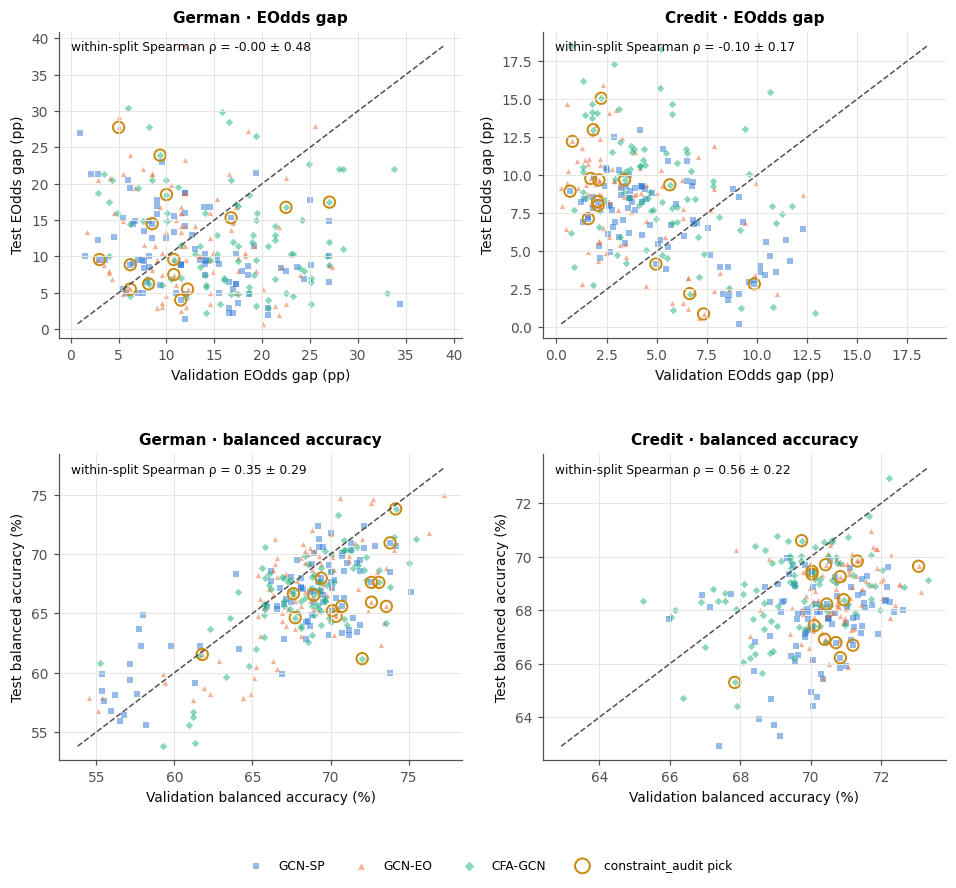

[35.3 min] saved Fig07_RQ4_validation_test_agreement


In [23]:
EF = ELIG[ELIG.method.isin(FAIR)]
def within_split_rho(df, a, b):
    return pd.DataFrame([dict(dataset=ds, seed=seed, method=m, rho=stats.spearmanr(g[a], g[b])[0])
                         for (ds, seed, m), g in df.groupby(["dataset", "seed", "method"])])

RHO = {met: within_split_rho(EF, f"val_{met}", met) for met in ["eodds", "bal_acc"]}
fig, axes = plt.subplots(2, len(DATASETS), figsize=(5.2 * len(DATASETS), 8.6), squeeze=False, gridspec_kw=dict(hspace=0.38))
for r_, (met, label) in enumerate([("eodds", "EOdds gap (pp)"), ("bal_acc", "balanced accuracy (%)")]):
    for c_, ds in enumerate(DATASETS):
        ax = axes[r_, c_]; d = EF[EF.dataset == ds]
        for m in FAIR:
            v = d[d.method == m]
            ax.scatter(v[f"val_{met}"], v[met], s=12, alpha=0.5, color=METHOD_COLOR[m], marker=METHOD_MARKER[m], lw=0, label=m)
        pick = SEL[(SEL.dataset == ds) & (SEL.selector == "constraint_audit")]
        ax.scatter(pick[f"val_{met}"], pick[met], s=55, facecolor="none", edgecolor=SELECTOR_COLOR["constraint_audit"], lw=1.3,
                   label="constraint_audit pick")
        lo, hi = min(d[f"val_{met}"].min(), d[met].min()), max(d[f"val_{met}"].max(), d[met].max())
        ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls="--")
        mr, hr = ci(RHO[met][RHO[met].dataset == ds].groupby("seed").rho.mean())
        ax.text(0.03, 0.97, f"within-split Spearman ρ = {mr:.2f} ± {np.nan_to_num(hr):.2f}", transform=ax.transAxes,
                va="top", fontsize=8, color=INK)
        ax.set_xlabel(f"Validation {label}"); ax.set_ylabel(f"Test {label}"); ax.set_title(f"{ds} · {label.split(' (')[0]}")
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=8, markerscale=1.3, bbox_to_anchor=(0.5, -0.02))
save_fig(fig, "Fig07_RQ4_validation_test_agreement", "Validation vs test metrics of deployable graph recipes, with within-split rank agreement")

### Cell 24 · Figure 8: sensitivity of the selectors to the utility budget (RQ4)
**What it does:** reruns the three selectors with the balanced-accuracy floor set to 0.5, 1, 2, 4 and 8 pp below the best validation balanced accuracy, and plots the resulting **test** EOdds (top) and test balanced accuracy (bottom). Values are averaged over fair methods within each split, then given a 95% CI over splits. utility_only ignores the budget and is a flat reference, and the dotted line marks the prespecified 2 pp budget. If the constraint_audit selector only helps at a budget that nobody would choose in advance, the RQ4 answer is negative.
**Main step:** M11 sensitivity analysis, **Figure 8 (RQ4)**.

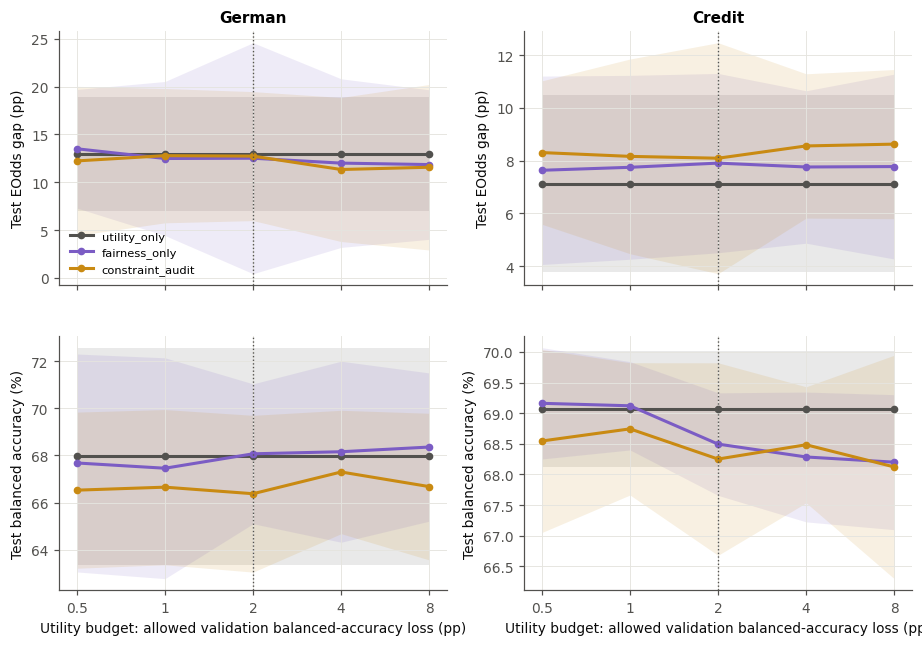

[35.4 min] saved Fig08_RQ4_utility_budget_sensitivity


In [24]:
BUD = pd.concat([select(t) for t in CFG["budget_grid"]], ignore_index=True)
BUD.to_csv(RAW_DIR / "selections_budget_scan.csv", index=False)
fig, axes = plt.subplots(2, len(DATASETS), figsize=(5.0 * len(DATASETS), 6.6), sharex=True, squeeze=False)
for c_, ds in enumerate(DATASETS):
    for r_, (met, label) in enumerate([("eodds", "Test EOdds gap (pp)"), ("bal_acc", "Test balanced accuracy (%)")]):
        ax = axes[r_, c_]
        for sel in SELECTORS:
            g = BUD[(BUD.dataset == ds) & (BUD.selector == sel)].groupby(["tol", "seed"])[met].mean().groupby(level="tol").agg(list)
            vals = [ci(v) for v in g]; mean = np.array([v[0] for v in vals]); half = np.nan_to_num([v[1] for v in vals])
            x = np.array(g.index)
            ax.plot(x, mean, color=SELECTOR_COLOR[sel], marker="o", ms=4, label=sel)
            ax.fill_between(x, mean - half, mean + half, color=SELECTOR_COLOR[sel], alpha=0.12, lw=0)
        ax.axvline(CFG["utility_tol"], color=INK2, lw=0.9, ls=":")
        ax.set_xscale("log", base=2); ax.set_xticks(CFG["budget_grid"]); ax.set_xticklabels([f"{t:g}" for t in CFG["budget_grid"]])
        ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
        ax.set_ylabel(label)
        if r_ == 0:
            ax.set_title(ds)
        else:
            ax.set_xlabel("Utility budget: allowed validation balanced-accuracy loss (pp)")
axes[0, 0].legend(fontsize=7.5)
save_fig(fig, "Fig08_RQ4_utility_budget_sensitivity", "Test EOdds and balanced accuracy of the selectors as the utility budget varies")

### Cell 25 · Table 8: selection stability and regret against a test oracle (RQ4)
**What it does:** for each dataset × fair method × selector, reports:
- **distinct_recipes:** how many different recipes the selector chose across the 5 splits, and the most frequent one (**modal_recipe**, with its share). A selector that picks a different graph in every split is not giving a reproducible recommendation.
- **eodds_regret:** test EOdds of the selected recipe minus that of a **test oracle**, which picks the fairest deployable recipe within the same 2 pp budget measured on test. Lower is better. It can be negative when the selector picks a recipe that misses the oracle's test-utility floor.
- **bal_acc_shortfall:** best deployable test balanced accuracy minus that of the selected recipe.
- **floor_relaxed:** how often the admissible family could not meet the floor.
- **val_test_rho_eodds:** the within-split validation–test rank correlation of EOdds from Figure 7.

All values are mean ± 95% CI over splits. The oracle uses test labels and only serves as a yardstick; it is never a deployable selector.
**Main step:** M11 evaluation, **Table 8 (RQ4)**.

In [25]:
ORC = []
for (ds, seed, m), el in EF.groupby(["dataset", "seed", "method"]):
    o = el[el.bal_acc >= el.bal_acc.max() - CFG["utility_tol"]].sort_values(["eodds", "bal_acc"], ascending=[True, False]).iloc[0]
    ORC.append(dict(dataset=ds, seed=seed, method=m, oracle_eodds=o.eodds, best_bal_acc=el.bal_acc.max()))
S8 = SEL.merge(pd.DataFrame(ORC), on=["dataset", "seed", "method"]).assign(
    recipe=lambda d: d.space + "/" + d.family + "/k" + d.k.astype(str),
    eodds_regret=lambda d: d.eodds - d.oracle_eodds, bal_acc_shortfall=lambda d: d.best_bal_acc - d.bal_acc)

def modal(r):
    vc = r.value_counts()
    return f"{vc.index[0]} ({vc.iloc[0]}/{len(r)})"

T8 = (S8.groupby(["dataset", "method", "selector"])
        .agg(distinct_recipes=("recipe", "nunique"), modal_recipe=("recipe", modal), eodds_regret=("eodds_regret", fmt),
             bal_acc_shortfall=("bal_acc_shortfall", fmt), floor_relaxed=("floor_relaxed", "sum")).reset_index())
T8 = T8.merge(RHO["eodds"].groupby(["dataset", "method"]).rho.agg(fmt).rename("val_test_rho_eodds").reset_index(),
              on=["dataset", "method"])
save_table(T8, "Table08_RQ4_selection_stability_and_regret",
           "Recipe stability across splits and test-oracle regret of validation-locked selectors (mean ± 95% CI over 5 splits)")

**Table08_RQ4_selection_stability_and_regret.** Recipe stability across splits and test-oracle regret of validation-locked selectors (mean ± 95% CI over 5 splits)

,dataset,method,selector,distinct_recipes,modal_recipe,eodds_regret,bal_acc_shortfall,floor_relaxed,val_test_rho_eodds,group_definition
0,Credit,CFA-GCN,constraint_audit,4,unaware/admissible/k5 (2/5),4.28 ± 2.61,2.67 ± 3.56,1,-0.16 ± 0.27,"Primary audit: S=1 for documented SEX=2, S=0 f..."
1,Credit,CFA-GCN,fairness_only,4,unaware/mutual/k5 (2/5),3.10 ± 3.73,1.82 ± 2.32,0,-0.16 ± 0.27,"Primary audit: S=1 for documented SEX=2, S=0 f..."
2,Credit,CFA-GCN,utility_only,4,legit/mutual/k5 (2/5),1.85 ± 3.41,1.22 ± 2.00,0,-0.16 ± 0.27,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,GCN-EO,constraint_audit,3,legit/admissible/k5 (3/5),3.13 ± 2.44,1.19 ± 1.62,0,-0.25 ± 0.18,"Primary audit: S=1 for documented SEX=2, S=0 f..."
4,Credit,GCN-EO,fairness_only,4,unaware/union/k5 (2/5),2.17 ± 0.43,1.41 ± 0.63,0,-0.25 ± 0.18,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,GCN-EO,utility_only,4,legit/mutual/k15 (2/5),1.73 ± 1.54,1.45 ± 0.89,0,-0.25 ± 0.18,"Primary audit: S=1 for documented SEX=2, S=0 f..."
6,Credit,GCN-SP,constraint_audit,4,legit/admissible/k15 (2/5),2.31 ± 2.10,1.99 ± 1.26,0,0.11 ± 0.23,"Primary audit: S=1 for documented SEX=2, S=0 f..."
7,Credit,GCN-SP,fairness_only,4,unaware/admissible/k5 (2/5),3.90 ± 1.58,1.88 ± 1.18,0,0.11 ± 0.23,"Primary audit: S=1 for documented SEX=2, S=0 f..."
8,Credit,GCN-SP,utility_only,3,legit/mutual/k5 (3/5),3.22 ± 1.97,0.73 ± 0.63,0,0.11 ± 0.23,"Primary audit: S=1 for documented SEX=2, S=0 f..."
9,German,CFA-GCN,constraint_audit,4,unaware/admissible/k5 (2/5),8.96 ± 6.69,4.60 ± 4.24,2,0.01 ± 0.67,"Sensitivity analysis: G=1 for Attribute9=A92, ..."


[35.4 min] saved Table08_RQ4_selection_stability_and_regret


## RQ5 · Persistence of fairness claims

### Cell 26 · Deployment jobs: retrain selected recipes transductively and inductively, then delete edges without retraining (M12)
**What it does:** for each dataset × split, retrains the vanilla GCN and each fair method on every recipe chosen by the *utility_only* or *constraint_audit* selector under two protocols:
- **transductive:** all persons in the graph, as in the anchor paper;
- **strict inductive:** reference graph from training persons only. Validation/test persons attach to references and receive messages, but references never receive query messages. Validation queries drive early stopping.

It then **deletes edges at random without retraining** (0–50%; 3 draws; symmetric reference edges and query attachments deleted independently), with the **same masks for the paired GCN and fair model**. Built-in checks confirm that (i) inductive reference rows contain no query neighbours and queries never connect to each other, and (ii) transductive retraining reproduces the grid result exactly.
**Main step:** M12. The data behind Figures 9–10 and Table 10.

In [26]:
def deploy_job(name, seed, recipes):
    torch.set_num_threads(1); warnings.filterwarnings("ignore")
    D = DATA[name]; P = prep(D, seed); y, s = D["y"], D["s"]; tr, va, te = P["split"]; n = len(y)
    out = dict(deploy=[], stress=[], preds=[], checks=[])
    for (space, family, k), methods in recipes.items():
        fam = build_families(P, space, k)[family]
        graphs = {"transductive": dict(sym=(fam["i"], fam["j"]), n=n, A=fam["A"], unsup=None),
                  "inductive": inductive_graph(P, space, family, k)}
        gi = graphs["inductive"]; Q = gi["A"][np.r_[va, te]]
        out["checks"].append(dict(check="inductive: references receive no query messages; no query-query edges",
                                  passed=bool(gi["A"][tr][:, np.r_[va, te]].nnz == 0 and Q[:, np.r_[va, te]].nnz == 0)))
        for proto, g in graphs.items():
            bundles = {}
            for m in ["GCN"] + methods:
                probs, bundle = fit(m, D, P, A=g["A"], unsup=g["unsup"], seed=seed); bundles[m] = (bundle, probs)
                out["deploy"].append(row(D, P, probs, seed=seed, space=space, family=family, k=k, protocol=proto, method=m))
                out["preds"].append(dict(dataset=name, seed=seed, space=space, family=family, k=k, protocol=proto, method=m,
                                         p=probs[te].tolist()))
            for rate in CFG["drop_rates"]:
                for rep in range(1 if rate == 0 else CFG["drop_repeats"]):
                    A_d = drop_edges(g, rate, np.random.default_rng(seed * 100 + rep))
                    for m, (bundle, probs) in bundles.items():
                        p = predict(bundle, A_d)
                        out["stress"].append(row(D, P, p, seed=seed, space=space, family=family, k=k, protocol=proto,
                                                 method=m, rate=rate, rep=rep))
    return out

tasks = []
for ds in ["Credit", "German"]:
    for seed in CFG["seeds"]:
        sel = SEL[(SEL.dataset == ds) & (SEL.seed == seed) & SEL.selector.isin(["utility_only", "constraint_audit"])]
        rec = {}
        for _, r_ in sel.iterrows():
            rec.setdefault((r_.space, r_.family, int(r_.k)), set()).add(r_.method)
        tasks.append((ds, seed, {k_: sorted(v) for k_, v in rec.items()}))
DEP_RES = run_jobs(deploy_job, tasks, "deployment")
DEP, STRESS = collect(DEP_RES, "deploy"), collect(DEP_RES, "stress")
PREDS = collect(DEP_RES, "preds"); CHECKS = pd.concat([CHECKS, collect(DEP_RES, "checks")], ignore_index=True)
DEP.to_csv(RAW_DIR / "runs_deployment.csv", index=False); STRESS.to_csv(RAW_DIR / "runs_edge_deletion.csv", index=False)
chk = DEP[DEP.protocol == "transductive"].merge(RUNS, on=["dataset", "seed", "space", "family", "k", "method"], suffixes=("", "_grid"))
CHECKS = pd.concat([CHECKS, pd.DataFrame([dict(check="transductive retraining reproduces the grid result",
                                               passed=bool(np.allclose(chk.eodds, chk.eodds_grid) and np.allclose(chk.bal_acc, chk.bal_acc_grid)))])])
print(f"deployment runs: {len(DEP)} | stress evaluations: {len(STRESS)}")

[35.4 min] deployment: starting 10 jobs


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 out of  10 | elapsed:  4.1min remaining:  4.1min
[Parallel(n_jobs=4)]: Done   7 out of  10 | elapsed:  4.4min remaining:  1.9min
[Parallel(n_jobs=4)]: Done  10 out of  10 | elapsed:  6.3min finished


deployment: 10 jobs in 6.4 min
deployment runs: 210 | stress evaluations: 2100


### Cell 27 · Figure 9: accuracy–fairness plane, transductive → inductive (RQ5)
**What it does:** for the recipes chosen by the **constraint_audit** selector, places each fair method in the plane of test EOdds against balanced accuracy (ideal = top-left). An arrow runs from the transductive position (filled marker) to the inductive position (hollow marker), with 95% CIs over splits. Logistic regression, the MLP and the majority classifier are graph-free references. The arrows show how much of the transductive operating point that papers report survives when scoring genuinely new applicants.
**Main step:** M12 analysis, **Figure 9 (RQ5)**.

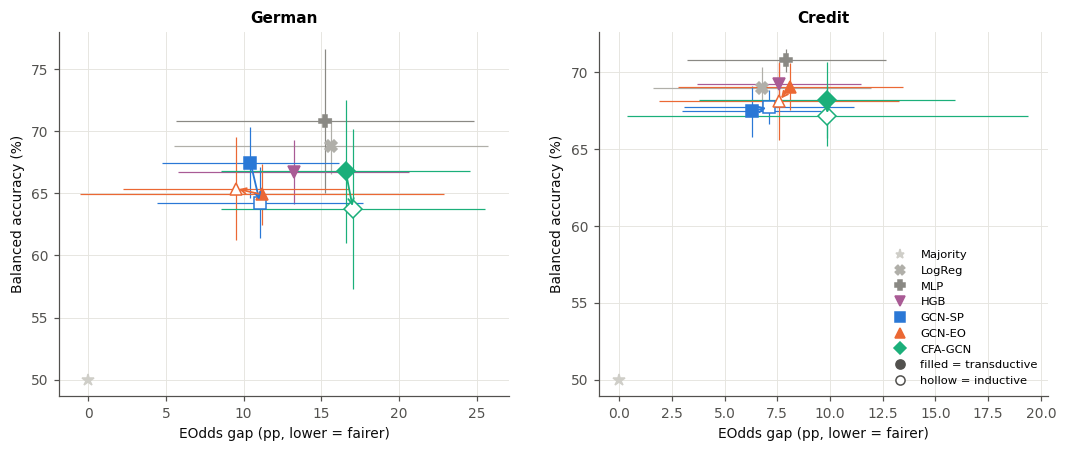

[41.7 min] saved Fig09_RQ5_transductive_to_inductive


In [27]:
cs = SEL[SEL.selector == "constraint_audit"][["dataset", "seed", "method", "space", "family", "k"]]
DSEL = DEP.merge(cs, on=["dataset", "seed", "method", "space", "family", "k"])
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.8 * len(DATASETS), 4.3), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    for m in TAB:
        v = TABR[(TABR.dataset == ds) & (TABR.method == m) & (TABR.node == "blind")]
        (x, xh), (y_, yh) = ci(v.eodds), ci(v.bal_acc)
        ax.errorbar(x, y_, xerr=np.nan_to_num(xh), yerr=np.nan_to_num(yh), fmt=METHOD_MARKER[m], color=METHOD_COLOR[m], ms=8, elinewidth=0.8)
    for m in FAIR:
        pts = {}
        for proto in ["transductive", "inductive"]:
            v = DSEL[(DSEL.dataset == ds) & (DSEL.method == m) & (DSEL.protocol == proto)]
            pts[proto] = (ci(v.eodds), ci(v.bal_acc))
            (x, xh), (y_, yh) = pts[proto]
            ax.errorbar(x, y_, xerr=np.nan_to_num(xh), yerr=np.nan_to_num(yh), fmt=METHOD_MARKER[m], color=METHOD_COLOR[m],
                        mfc=METHOD_COLOR[m] if proto == "transductive" else "white", ms=8, elinewidth=0.8)
        ax.annotate("", xy=(pts["inductive"][0][0], pts["inductive"][1][0]), xytext=(pts["transductive"][0][0], pts["transductive"][1][0]),
                    arrowprops=dict(arrowstyle="->", color=METHOD_COLOR[m], lw=1.2))
    ax.set_xlabel("EOdds gap (pp, lower = fairer)"); ax.set_ylabel("Balanced accuracy (%)"); ax.set_title(ds)
handles = ([Line2D([], [], color=METHOD_COLOR[m], marker=METHOD_MARKER[m], ls="", label=m) for m in TAB + FAIR]
           + [Line2D([], [], color=INK2, marker="o", ls="", label="filled = transductive"),
              Line2D([], [], color=INK2, marker="o", mfc="white", ls="", label="hollow = inductive")])
axes[0, -1].legend(handles=handles, fontsize=7.5, loc="lower right")
save_fig(fig, "Fig09_RQ5_transductive_to_inductive", "Constraint-selected recipes: accuracy–fairness shift from transductive to inductive scoring")

### Cell 28 · Figure 10: fairness gains under edge deletion without retraining (RQ5)
**What it does:** for the constraint-selected recipes, plots the paired EOdds gain of each fair method over the vanilla GCN, with both models evaluated under **identical** deletion masks, against the share of edges deleted. Solid lines are transductive, dashed lines inductive. Draws are averaged within each split before the 95% CI over splits is computed. A gain that collapses at small deletion rates depends on the exact edge set.
**Main step:** M12 robustness analysis, **Figure 10 (RQ5)**.

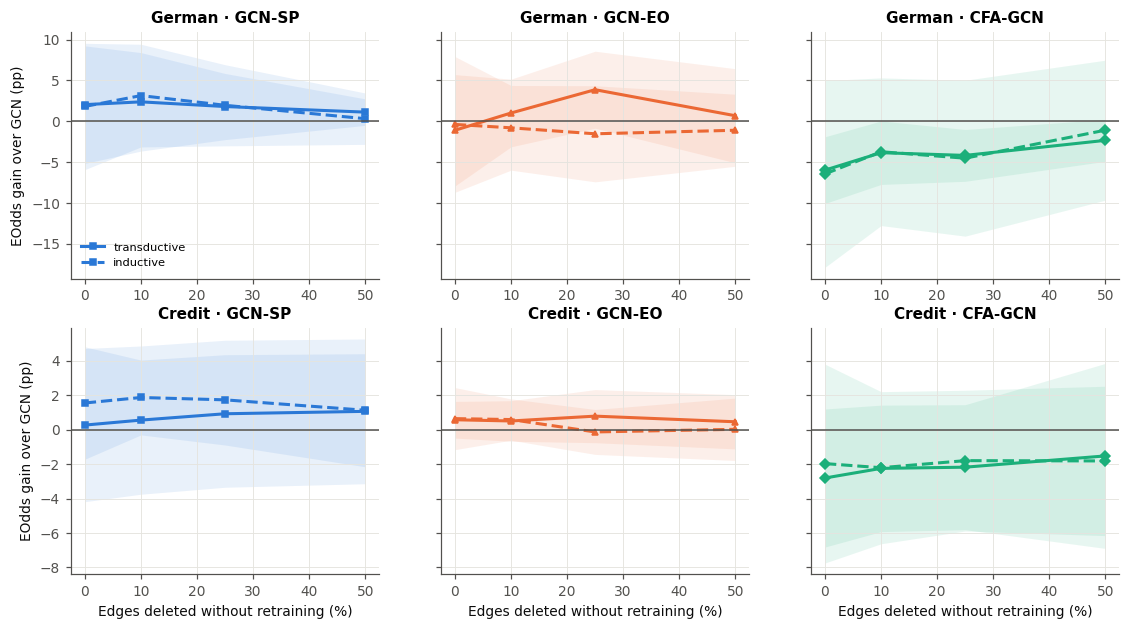

[41.8 min] saved Fig10_RQ5_edge_deletion_robustness


In [28]:
st_ = STRESS.merge(cs.rename(columns={"method": "sel_method"}), on=["dataset", "seed", "space", "family", "k"])
st_ = st_[(st_.method == st_.sel_method) | (st_.method == "GCN")]
pv = st_.pivot_table(index=["dataset", "seed", "sel_method", "protocol", "rate", "rep"], columns="method", values="eodds")
rows_ = []
for m in FAIR:
    sub = pv[pv.index.get_level_values("sel_method") == m]
    g = (sub["GCN"] - sub[m]).groupby(level=["dataset", "seed", "protocol", "rate"]).mean().reset_index(name="gain")
    rows_.append(g.assign(method=m))
DEL = pd.concat(rows_, ignore_index=True)
fig, axes = plt.subplots(len(DATASETS), len(FAIR), figsize=(4.1 * len(FAIR), 3.2 * len(DATASETS)), sharey="row", squeeze=False)
for r_, ds in enumerate(DATASETS):
    for c_, m in enumerate(FAIR):
        ax = axes[r_, c_]
        for proto, ls in [("transductive", "-"), ("inductive", "--")]:
            gg = DEL[(DEL.dataset == ds) & (DEL.method == m) & (DEL.protocol == proto)].groupby("rate")["gain"].agg(list)
            vals = [ci(v) for v in gg]; mean = np.array([v[0] for v in vals]); half = np.nan_to_num([v[1] for v in vals])
            x = np.array(gg.index) * 100
            ax.plot(x, mean, color=METHOD_COLOR[m], ls=ls, marker=METHOD_MARKER[m], ms=4.5, label=proto)
            ax.fill_between(x, mean - half, mean + half, color=METHOD_COLOR[m], alpha=0.10, lw=0)
        ax.axhline(0, color=INK2, lw=1); ax.set_title(f"{ds} · {m}")
        if c_ == 0:
            ax.set_ylabel("EOdds gain over GCN (pp)")
        if r_ == len(DATASETS) - 1:
            ax.set_xlabel("Edges deleted without retraining (%)")
axes[0, 0].legend(fontsize=7.5)
save_fig(fig, "Fig10_RQ5_edge_deletion_robustness", "Paired EOdds gains under random edge deletion without retraining")

### Cell 29 · Recipe agreement and source-selected recipe portability (RQ5)
For each fair method, compare recipe-level mean EOdds gains over matched GCN across the two settings. Kendall tau and sign agreement are descriptive; the code does not report a p-value. `interval_above_zero_both` is a descriptive interval rule, not confirmation across demographic populations.

Portability chooses the `unaware`/`legit` recipe with highest **mean source-validation paired gain**, aggregated over source splits. This is not M11's constraint selector, has no utility floor and does not minimize absolute validation disparity. Ties use space/family/k. Read its destination test gain from that recipe's separately fitted destination runs, without destination recipe reselection. The destination maximum test gain is an explicitly labelled retrospective oracle only.

Portable settings are space policy, family and k, together with the notebook's fixed hyperparameters/constraint rules. Destination preprocessing, screened field identities, numerical per-space cutoffs, edges and model parameters are fitted locally. No weights are transferred. German G and Credit S are different targets: portability is not independent replication of a common sex-fairness effect or transfer learning.

In [29]:
VGAINS = paired_gain(RUNS, RKEYS, col="val_eodds")
T9 = []
for m in FAIR:
    gm = GAINS[GAINS.method == m].assign(sig=lambda d: d.lo > 0)
    a = gm.pivot_table(index=["space", "family", "k"], columns="dataset", values="gain").dropna()
    sg = gm.pivot_table(index=["space", "family", "k"], columns="dataset", values="sig").astype(bool)
    tau = stats.kendalltau(a["German"], a["Credit"]).statistic
    r9 = dict(method=m, analysis_scope="recipe portability across different group definitions; not sex-fairness replication", recipes=len(a), kendall_tau=round(tau, 3),
              sign_agreement=f"{(np.sign(a.German) == np.sign(a.Credit)).mean():.0%}",
              interval_above_zero_both=int((sg.German & sg.Credit).sum()))
    for src, dst in [("German", "Credit"), ("Credit", "German")]:
        v = VGAINS[(VGAINS.method == m) & (VGAINS.dataset == src) & VGAINS.space.isin(["unaware", "legit"])]
        b = v.sort_values(["gain", "space", "family", "k"], ascending=[False, True, True, True]).iloc[0]
        tg = GAINS[(GAINS.method == m) & (GAINS.dataset == dst)]
        t = tg[(tg.space == b.space) & (tg.family == b.family) & (tg.k == b.k)].iloc[0]
        r9[f"{src}→{dst} recipe"] = f"{b.space}/{b.family}/k{b.k}"
        r9[f"{src}→{dst} test gain"] = f"{t.gain:.2f} ± {np.nan_to_num(t.half):.2f}"
        r9[f"{dst} best deployable test gain"] = round(tg[tg.space.isin(["unaware", "legit"])].gain.max(), 2)
    T9.append(r9)
T9 = pd.DataFrame(T9)
save_table(T9, "Table09_RQ5_cross_dataset_agreement",
           "Recipe portability: source mean-validation-gain choice; destination fits reused, no destination recipe reselection")

**Table09_RQ5_cross_dataset_agreement.** Recipe portability: source mean-validation-gain choice; destination fits reused, no destination recipe reselection

,method,analysis_scope,recipes,kendall_tau,sign_agreement,interval_above_zero_both,German→Credit recipe,German→Credit test gain,Credit best deployable test gain,Credit→German recipe,Credit→German test gain,German best deployable test gain
0,GCN-SP,recipe portability across different group defi...,27,0.499,78%,3,unaware/mutual/k30,2.00 ± 1.44,3.33,unaware/admissible/k5,0.79 ± 7.05,7.60
1,GCN-EO,recipe portability across different group defi...,27,0.288,56%,0,unaware/mutual/k30,0.53 ± 2.35,2.25,unaware/union/k30,-8.17 ± 7.95,6.45
2,CFA-GCN,recipe portability across different group defi...,27,-0.048,37%,0,unaware/mutual/k30,0.63 ± 3.75,1.39,legit/admissible/k15,-0.11 ± 6.60,7.64


[41.8 min] saved Table09_RQ5_cross_dataset_agreement


### Cell 30 · Table 10: persistence matrix with stratified bootstrap (RQ5)
**What it does:** for each dataset × fair method, tests two claims under five conditions:
1. the anchor-style recipe (full space, union, *k* = 15, transductive);
2. the constraint-selected recipe, transductive;
3. the same recipe, inductive;
4. the inductive recipe with 25% of edges deleted without retraining;
5. the fixed admissible graph in the unaware space at k = 15, transductive (not a matched-random contrast).

**Claim A:** EOdds gain over GCN on the same graph. **Claims B/C:** EOdds gain over the graph-free MLP / HGB, losing no more than 1 pp of mean balanced accuracy. Both are paired over 5 splits (95% t-CI). For conditions 2–3, a **stratified person bootstrap** on the primary split (1,000 resamples within outcome × group cells; conditional on the trained models) adds a second interval. A claim *persists* if its CI is entirely above 0. The last columns summarize the descriptive rule across different benchmark groupings; they do not establish replication of a common sex-fairness claim.
**Main step:** M12 synthesis, **Table 10 (RQ5)**.

In [30]:
def boot_gain(y, s, pa, pb, reps, seed=1234):
    rng = np.random.default_rng(seed); cells = [np.flatnonzero((y == c) & (s == g)) for c in (0, 1) for g in (0, 1)]
    out = []
    for _ in range(reps):
        idx = np.concatenate([rng.choice(c, len(c), replace=True) for c in cells])
        out.append(metrics(y[idx], s[idx], pa[idx])["eodds"] - metrics(y[idx], s[idx], pb[idx])["eodds"])
    return np.quantile(out, [0.025, 0.975])

mlp_b = TABR[(TABR.method == "MLP") & (TABR.node == "blind")].set_index(["dataset", "seed"])
hgb_b = TABR[(TABR.method == "HGB") & (TABR.node == "blind")].set_index(["dataset", "seed"])
def claim_rows(ds, m, cond, df):  # df: one row per seed with columns eodds_GCN, eodds_m, bal_acc_m
    a = ci(df.eodds_GCN - df.eodds_m); mm = mlp_b.loc[[(ds, s_) for s_ in df.seed]]
    b = ci(mm.eodds.values - df.eodds_m.values); acc = ci(df.bal_acc_m.values - mm.bal_acc.values)
    hh = hgb_b.loc[[(ds, s_) for s_ in df.seed]]
    hgain = ci(hh.eodds.values - df.eodds_m.values); hacc = ci(df.bal_acc_m.values - hh.bal_acc.values)
    return dict(dataset=ds, method=m, condition=cond, n_splits=len(df),
                gain_vs_GCN=f"{a[0]:.2f} ± {np.nan_to_num(a[1]):.2f}", persists_vs_GCN=bool(a[0] - np.nan_to_num(a[1]) > 0),
                gain_vs_MLP=f"{b[0]:.2f} ± {np.nan_to_num(b[1]):.2f}", bal_acc_diff_vs_MLP=f"{acc[0]:.2f} ± {np.nan_to_num(acc[1]):.2f}",
                persists_vs_MLP=bool(b[0] - np.nan_to_num(b[1]) > 0 and acc[0] >= -1.0),
                gain_vs_HGB=f"{hgain[0]:.2f} ± {np.nan_to_num(hgain[1]):.2f}",
                bal_acc_diff_vs_HGB=f"{hacc[0]:.2f} ± {np.nan_to_num(hacc[1]):.2f}",
                persists_vs_HGB=bool(hgain[0] - np.nan_to_num(hgain[1]) > 0 and hacc[0] >= -1.0))

def wide(df, m, idx):
    pv = df[df.method.isin(["GCN", m])].pivot_table(index=idx, columns="method", values=["eodds", "bal_acc"])
    return pd.DataFrame(dict(seed=pv.index.get_level_values("seed"), eodds_GCN=pv["eodds"]["GCN"].values,
                             eodds_m=pv["eodds"][m].values, bal_acc_m=pv["bal_acc"][m].values))

T10 = []; rate_ref = 0.25 if 0.25 in CFG["drop_rates"] else max(CFG["drop_rates"])
for ds in DATASETS:
    y, s = DATA[ds]["y"], DATA[ds]["s"]; te = prep(DATA[ds], CFG["primary_seed"])["split"][2]
    for m in FAIR:
        anc = RUNS[(RUNS.dataset == ds) & (RUNS.space == "full") & (RUNS.family == "union") & (RUNS.k == CFG["ref_k"])]
        T10.append(claim_rows(ds, m, "1 anchor-style (full, union, k=15), transductive", wide(anc, m, ["seed"])))
        sel_m = cs[(cs.dataset == ds) & (cs.method == m)]
        for proto, label in [("transductive", "2 constraint-selected, transductive"), ("inductive", "3 constraint-selected, inductive")]:
            d_ = DEP[(DEP.dataset == ds) & (DEP.protocol == proto)].merge(sel_m.drop(columns="method"), on=["dataset", "seed", "space", "family", "k"])
            r_ = claim_rows(ds, m, label, wide(d_, m, ["seed"]))
            ps = sel_m[sel_m.seed == CFG["primary_seed"]].iloc[0]
            pr = PREDS[(PREDS.dataset == ds) & (PREDS.seed == CFG["primary_seed"]) & (PREDS.protocol == proto)
                       & (PREDS.space == ps.space) & (PREDS.family == ps.family) & (PREDS.k == ps.k)].set_index("method")
            lo, hi = boot_gain(y[te], s[te], np.array(pr.loc["GCN", "p"]), np.array(pr.loc[m, "p"]), CFG["n_boot"])
            r_.update(bootstrap_primary_split=f"[{lo:.2f}, {hi:.2f}]"); T10.append(r_)
        d_ = STRESS[(STRESS.dataset == ds) & (STRESS.protocol == "inductive") & (STRESS.rate == rate_ref)].merge(
            sel_m.drop(columns="method"), on=["dataset", "seed", "space", "family", "k"])
        d_ = d_.groupby(["seed", "method"])[["eodds", "bal_acc"]].mean().reset_index()
        T10.append(claim_rows(ds, m, f"4 constraint-selected, inductive, {int(rate_ref * 100)}% edges deleted", wide(d_, m, ["seed"])))
        adm = RUNS[(RUNS.dataset == ds) & (RUNS.space == "unaware") & (RUNS.family == "admissible") & (RUNS.k == CFG["ref_k"])]
        T10.append(claim_rows(ds, m, "5 admissible graph (unaware, k=15), transductive", wide(adm, m, ["seed"])))
T10 = pd.DataFrame(T10)
summary = T10.groupby("method")[["persists_vs_GCN", "persists_vs_MLP", "persists_vs_HGB"]].all().add_suffix("_everywhere").reset_index()
T10 = T10.merge(summary, on="method")
save_table(T10, "Table10_RQ5_persistence_matrix", "Persistence of fairness claims across conditions and datasets (paired t-CI; bootstrap on primary split)")

**Table10_RQ5_persistence_matrix.** Persistence of fairness claims across conditions and datasets (paired t-CI; bootstrap on primary split)

,dataset,method,condition,n_splits,gain_vs_GCN,persists_vs_GCN,gain_vs_MLP,bal_acc_diff_vs_MLP,persists_vs_MLP,gain_vs_HGB,bal_acc_diff_vs_HGB,persists_vs_HGB,bootstrap_primary_split,persists_vs_GCN_everywhere,persists_vs_MLP_everywhere,persists_vs_HGB_everywhere,group_definition
0,German,GCN-SP,"1 anchor-style (full, union, k=15), transductive",5,11.08 ± 6.11,True,0.99 ± 13.60,-10.64 ± 11.54,False,-1.05 ± 9.76,-6.52 ± 7.82,False,NaN,False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
1,German,GCN-SP,"2 constraint-selected, transductive",5,2.04 ± 7.19,False,4.81 ± 6.74,-3.36 ± 3.86,False,2.77 ± 8.03,0.76 ± 2.83,False,"[-11.00, 13.64]",False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
2,German,GCN-SP,"3 constraint-selected, inductive",5,1.82 ± 7.73,False,4.20 ± 14.30,-6.60 ± 6.63,False,2.16 ± 8.40,-2.48 ± 1.05,False,"[-18.43, 29.35]",False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
3,German,GCN-SP,"4 constraint-selected, inductive, 25% edges de...",5,1.96 ± 4.96,False,4.26 ± 12.26,-6.11 ± 5.47,False,2.22 ± 7.95,-1.99 ± 1.81,False,NaN,False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
4,German,GCN-SP,"5 admissible graph (unaware, k=15), transductive",5,0.05 ± 4.35,False,2.96 ± 11.01,-5.19 ± 9.01,False,0.92 ± 4.50,-1.07 ± 5.55,False,NaN,False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
5,German,GCN-EO,"1 anchor-style (full, union, k=15), transductive",5,5.68 ± 5.26,True,-4.41 ± 7.36,-6.76 ± 3.44,False,-6.45 ± 9.34,-2.64 ± 3.30,False,NaN,False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
6,German,GCN-EO,"2 constraint-selected, transductive",5,-1.10 ± 6.81,False,4.09 ± 15.70,-5.93 ± 4.55,False,2.05 ± 5.19,-1.81 ± 3.09,False,"[-16.99, 13.47]",False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
7,German,GCN-EO,"3 constraint-selected, inductive",5,-0.38 ± 8.31,False,5.76 ± 14.90,-5.45 ± 5.68,False,3.71 ± 6.37,-1.33 ± 2.93,False,"[-13.16, 16.99]",False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
8,German,GCN-EO,"4 constraint-selected, inductive, 25% edges de...",5,-1.53 ± 5.88,False,3.96 ± 14.59,-6.25 ± 5.30,False,1.92 ± 7.75,-2.13 ± 2.50,False,NaN,False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
9,German,GCN-EO,"5 admissible graph (unaware, k=15), transductive",5,-2.58 ± 8.72,False,0.33 ± 12.89,-4.21 ± 4.28,False,-1.71 ± 5.19,-0.10 ± 5.32,False,NaN,False,False,False,"Sensitivity analysis: G=1 for Attribute9=A92, ..."


[44.0 min] saved Table10_RQ5_persistence_matrix


### Cell 31 · Supporting tables: anchor-style reference results and method verification (S3, S4) · RQ1–RQ5
**What it does:**
- **Table S3** reports all models at two reference recipes in the format of the anchor paper's Table 3, extended with balanced accuracy and EOdds and with 95% CIs over splits: the *full* union *k* = 15 graph (the audit-group category inside the similarity, diagnostic only) and the *unaware* union *k* = 15 graph.
- **Table S4** lists every built-in verification check and whether it passed.
- **S5** reports paired audit-minus-matched-random effects (retrained and fixed model).
- **S6** isolates admissible-family restriction from the minimax selection objective on the same strict feasible floor; infeasible splits are counted as abstentions.
- **S7** reports the attribute-free structural probe separately from propagated features.

**Main step:** M13 supporting evidence.

In [31]:
ref = RUNS[(RUNS.family == "union") & (RUNS.k == CFG["ref_k"]) & RUNS.space.isin(["full", "unaware"])]
tab = TABR[TABR.node == "blind"].assign(space="(no graph)")
S3 = (pd.concat([tab, ref]).groupby(["dataset", "space", "method"])
        .agg(**{c: (c, fmt) for c in ["acc", "bal_acc", "auc", "dsp", "deo", "eodds"]}).reset_index())
S3 = S3.sort_values(["dataset", "space", "method"], key=lambda c: c.map({m: i for i, m in enumerate(TAB + GNN)}) if c.name == "method" else c)
save_table(S3, "TableS3_reference_configuration_results", "Anchor-style results at union k=15 (full and unaware spaces) and tabular baselines")
S4 = CHECKS.groupby("check").passed.agg(["all", "size"]).reset_index().rename(columns={"all": "all_passed", "size": "times_checked"})
save_table(S4, "TableS4_method_verification", "Built-in method verification checks")
assert S4.all_passed.all(), "a verification check failed"

# Direct paired effects answer whether constraints differ from edge-count controls.
pair = dA.merge(dR, on=key, suffixes=("_audit", "_random"))
for metric in ["eodds", "bal_acc"]:
    pair[f"d_{metric}"] = pair[f"{metric}_audit"] - pair[f"{metric}_random"]
pair = pair.groupby(["dataset", "seed", "space", "method"])[["d_eodds", "d_bal_acc"]].mean().reset_index()
pair = pair.assign(phase="retrained", comparison="all_constraints", random_draws=CFG["retrain_random_draws"])
fixed_pairs = []
for filt in ["legitimacy", "distance", "degree", "all_constraints"]:
    join = ["dataset", "seed", "space", "method"]
    a = iv[iv.intervention == filt]; b = iv[iv.intervention == f"random_{filt}"]
    z = a.merge(b, on=join, suffixes=("_audit", "_random"))
    assert np.allclose(z.retained_audit, z.retained_random), "mismatched fixed-model control budget"
    for metric in ["eodds", "bal_acc"]:
        z[f"d_{metric}"] = z[f"d_{metric}_audit"] - z[f"d_{metric}_random"]
    fixed_pairs.append(z[join + ["d_eodds", "d_bal_acc"]].assign(
        phase="fixed_model", comparison=filt, random_draws=CFG["drop_repeats"]))
PAIRED_CONTROLS = pd.concat([pair] + fixed_pairs, ignore_index=True)
PAIRED_CONTROLS.to_csv(RAW_DIR / "audit_paired_controls.csv", index=False)
S5 = PAIRED_CONTROLS.groupby(["dataset", "space", "method", "phase", "comparison"]).agg(
    d_eodds_audit_minus_random=("d_eodds", fmt), d_bal_acc_audit_minus_random=("d_bal_acc", fmt),
    n_splits=("seed", "nunique"), random_draws=("random_draws", "first")).reset_index()
save_table(S5, "TableS5_RQ3_paired_audit_controls",
           "Audit minus edge-count-matched random control; draws and k averaged within split; descriptive split intervals")

S6 = CONTROLLED.groupby(["dataset", "method"]).agg(
    feasible_splits=("feasible", "sum"), total_splits=("seed", "size"),
    family_only_d_eodds=("family_only_d_eodds", fmt), family_only_d_bal_acc=("family_only_d_bal_acc", fmt),
    minimax_d_eodds=("minimax_d_eodds", fmt), minimax_d_bal_acc=("minimax_d_bal_acc", fmt)).reset_index()
save_table(S6, "TableS6_RQ4_controlled_selector_ablation",
           "Same utility floor: family restriction then minimax objective; infeasible splits abstain, contrasts are feasible-split conditional")

S7 = TOPOLOGY_PROBES.groupby(["dataset", "space", "family", "probe"]).agg(
    held_out_group_auc=("auc", fmt), n_splits=("seed", "nunique")).reset_index()
save_table(S7, "TableS7_RQ2_topology_only_probe",
           "Attribute-free degree/neighbour-degree/isolation linear probe; limited structural descriptors, not a bound on all topology information")

**TableS3_reference_configuration_results.** Anchor-style results at union k=15 (full and unaware spaces) and tabular baselines

,dataset,space,method,acc,bal_acc,auc,dsp,deo,eodds,group_definition
3,Credit,(no graph),Majority,77.90 ± 0.00,50.00 ± 0.00,50.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,"Primary audit: S=1 for documented SEX=2, S=0 f..."
1,Credit,(no graph),LogReg,75.24 ± 0.87,69.00 ± 1.32,75.21 ± 0.98,6.34 ± 4.30,5.06 ± 4.99,6.80 ± 5.17,"Primary audit: S=1 for documented SEX=2, S=0 f..."
2,Credit,(no graph),MLP,75.10 ± 0.99,70.79 ± 0.75,75.61 ± 1.80,6.77 ± 3.87,5.59 ± 5.69,7.93 ± 4.73,"Primary audit: S=1 for documented SEX=2, S=0 f..."
0,Credit,(no graph),HGB,75.50 ± 2.02,69.27 ± 1.33,74.76 ± 1.53,6.32 ± 4.87,4.93 ± 5.07,7.57 ± 3.89,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,full,GCN,70.90 ± 2.28,67.84 ± 1.69,73.58 ± 2.10,8.94 ± 4.80,7.53 ± 7.59,12.42 ± 6.01,"Primary audit: S=1 for documented SEX=2, S=0 f..."
7,Credit,full,GCN-SP,69.24 ± 2.13,66.71 ± 0.69,72.56 ± 1.20,4.24 ± 3.19,4.51 ± 4.71,7.80 ± 1.97,"Primary audit: S=1 for documented SEX=2, S=0 f..."
6,Credit,full,GCN-EO,70.20 ± 2.75,67.42 ± 1.61,73.12 ± 1.65,6.46 ± 6.25,5.51 ± 7.95,10.17 ± 5.20,"Primary audit: S=1 for documented SEX=2, S=0 f..."
4,Credit,full,CFA-GCN,70.62 ± 1.62,66.98 ± 2.29,72.53 ± 1.94,8.20 ± 4.47,6.55 ± 5.75,13.07 ± 2.70,"Primary audit: S=1 for documented SEX=2, S=0 f..."
9,Credit,unaware,GCN,71.36 ± 1.03,67.97 ± 1.20,73.34 ± 1.69,7.11 ± 1.98,5.34 ± 3.70,9.53 ± 4.95,"Primary audit: S=1 for documented SEX=2, S=0 f..."
11,Credit,unaware,GCN-SP,68.98 ± 3.32,66.77 ± 2.33,72.62 ± 0.88,4.35 ± 4.14,5.34 ± 4.71,6.69 ± 3.69,"Primary audit: S=1 for documented SEX=2, S=0 f..."


[44.0 min] saved TableS3_reference_configuration_results


**TableS4_method_verification.** Built-in method verification checks

,check,all_passed,times_checked
0,"admissible graphs satisfy legitimacy, distance...",True,90
1,each fixed-model random control matches its fi...,True,240
2,graphs are symmetric without self-loops,True,270
3,inductive: references receive no query message...,True,47
4,retraining random controls exactly match admis...,True,180
5,transductive retraining reproduces the grid re...,True,1


[44.0 min] saved TableS4_method_verification


... (5 outputs left out)

[44.0 min] saved TableS6_RQ4_controlled_selector_ablation


**TableS7_RQ2_topology_only_probe.** Attribute-free degree/neighbour-degree/isolation linear probe; limited structural descriptors, not a bound on all topology information

,dataset,space,family,probe,held_out_group_auc,n_splits,group_definition
0,Credit,full,admissible,degree_neighbour_degree_isolation,0.72 ± 0.02,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
1,Credit,full,union,degree_neighbour_degree_isolation,0.58 ± 0.02,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
2,Credit,legit,admissible,degree_neighbour_degree_isolation,0.50 ± 0.02,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
3,Credit,legit,union,degree_neighbour_degree_isolation,0.52 ± 0.01,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
4,Credit,unaware,admissible,degree_neighbour_degree_isolation,0.50 ± 0.01,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
5,Credit,unaware,union,degree_neighbour_degree_isolation,0.53 ± 0.01,5,"Primary audit: S=1 for documented SEX=2, S=0 f..."
6,German,full,admissible,degree_neighbour_degree_isolation,0.77 ± 0.20,5,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
7,German,full,union,degree_neighbour_degree_isolation,0.60 ± 0.06,5,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
8,German,legit,admissible,degree_neighbour_degree_isolation,0.60 ± 0.06,5,"Sensitivity analysis: G=1 for Attribute9=A92, ..."
9,German,legit,union,degree_neighbour_degree_isolation,0.57 ± 0.07,5,"Sensitivity analysis: G=1 for Attribute9=A92, ..."


[44.0 min] saved TableS7_RQ2_topology_only_probe


### Cell 32 · Key findings per research question (M13)
**What it does:** extracts the headline numbers from Tables 1–10 into a short text per RQ, so the manuscript's results paragraphs can be checked against the executed runs. The text is saved as `key_findings.md`.
**Main step:** M13 synthesis, connecting the results to RQ1–RQ5.

In [32]:
L = ["Interpretation: Credit is the primary documented-SEX audit; German is the A92-vs-other grouping sensitivity analysis, not verified female/male membership.",
     "CFA-GCN is a mechanism-inspired approximation, not complete FCLCA. Intervals and persistence indicators are descriptive.",
     "Cross-dataset agreement and portability concern different group definitions; they do not replicate a common sex-fairness effect."]
for ds in DATASETS:
    a = T2A[T2A.dataset == ds]; b = T2B[(T2B.dataset == ds) & (T2B.outcome == "eodds")].iloc[0]
    L.append(f"- **RQ1 · {ds}:** recipe-level mean EOdds gains over GCN range "
             f"{a.min_recipe_gain.min():.1f} to {a.max_recipe_gain.max():.1f} pp; "
             + "; ".join(f"{r_.method}: {r_.recipes_interval_above_zero}/{r_.recipes} intervals above zero, "
                         f"{r_.recipes_interval_below_zero} intervals below zero, sign reversals in {r_.splits_with_sign_reversal} splits, "
                         f"beats LogReg on balanced accuracy in {r_.share_runs_bal_acc_above_logreg:.0%} of runs, "
                         f"HGB in {r_.share_runs_bal_acc_above_hgb:.0%}" for r_ in a.itertuples())
             + f". η² construction = {b.eta2_construction:.2f} vs method = {b.eta2_method:.2f}; Kendall's W = {b.kendall_W_eodds_ranks:.2f}.")
for ds in DATASETS:
    g = T1[(T1.dataset == ds) & (T1.family == "union") & (T1.k == CFG["ref_k"])].set_index("space")["excess_h_sens"]
    pr = PROBES[(PROBES.dataset == ds) & (PROBES.family == "union")].groupby(["space", "hop"])["auc"].mean()
    ab = AB[(AB.dataset == ds) & (AB.method == "GCN")].groupby(["node", "topology"])["eodds"].mean()
    L.append(f"- **RQ2 · {ds} ({GROUP_LABEL[ds]}):** excess group homophily (union, k={CFG['ref_k']}) full {g['full']:.3f}, unaware {g['unaware']:.3f}, "
             f"legit {g['legit']:.3f}; probe AUC inputs {pr[('unaware', 0)]:.3f} → 2 hops unaware {pr[('unaware', 2)]:.3f}, "
             f"full {pr[('full', 2)]:.3f}; GCN EOdds blind/blind {ab[('blind', 'blind')]:.1f}, pruned topology {ab[('blind', 'pruned')]:.1f}, "
             f"pruned features {ab[('pruned', 'blind')]:.1f}, both {ab[('pruned', 'pruned')]:.1f} pp.")
for ds in DATASETS:
    t = T5[(T5.dataset == ds) & (T5.k == CFG["ref_k"])].set_index("space")
    L.append(f"- **RQ3 · {ds}:** IER (union, k={CFG['ref_k']}) full {t.loc['full', 'IER']:.1%} (same-group {t.loc['full', 'IER_same']:.1%}, "
             f"cross-group {t.loc['full', 'IER_cross']:.1%}); unaware {t.loc['unaware', 'IER']:.1%}. Excess homophily full: union "
             f"{t.loc['full', 'excess_h_union']:.3f} → admissible {t.loc['full', 'excess_h_admissible']:.3f} vs matched random "
             f"{t.loc['full', 'excess_h_random_matched']:.3f}.")
    for sp in ["full", "unaware"]:
        ea = ci(dA[(dA.dataset == ds) & (dA.space == sp)].groupby("seed").eodds.mean()); er = ci(dR[(dR.dataset == ds) & (dR.space == sp)].groupby("seed").eodds.mean())
        L.append(f"  - {sp}: retrained ΔEOdds admissible {ea[0]:.2f} ± {np.nan_to_num(ea[1]):.2f} vs matched random {er[0]:.2f} ± {np.nan_to_num(er[1]):.2f} pp (all GNNs, all k).")
for ds in DATASETS:
    s7 = SEL[SEL.dataset == ds].groupby("selector")[["bal_acc", "eodds", "gain_vs_gcn"]].mean()
    L.append(f"- **RQ4 · {ds} selectors (mean over methods/splits):** " + "; ".join(
        f"{k_}: bal. acc. {v.bal_acc:.1f}, EOdds {v.eodds:.1f}, gain vs GCN {v.gain_vs_gcn:.2f}" for k_, v in s7.iterrows()) + ".")
    rho = {met: ci(RHO[met][RHO[met].dataset == ds].groupby("seed").rho.mean())[0] for met in RHO}
    s8 = S8[S8.dataset == ds].groupby("selector").agg(regret=("eodds_regret", "mean"), distinct=("recipe", "nunique"))
    bud = BUD[BUD.dataset == ds].groupby(["selector", "tol"]).eodds.mean().unstack()
    L.append(f"  - validation–test Spearman ρ: EOdds {rho['eodds']:.2f}, balanced accuracy {rho['bal_acc']:.2f}; test-oracle EOdds regret "
             + ", ".join(f"{k_} {v.regret:.2f}" for k_, v in s8.iterrows())
             + "; constraint_audit minus fairness_only test EOdds across budgets "
             + ", ".join(f"{t_:g} pp: {bud.loc['constraint_audit', t_] - bud.loc['fairness_only', t_]:+.2f}" for t_ in bud.columns) + ".")
for r_ in T9.itertuples():
    L.append(f"- **RQ5 · {r_.method} across datasets:** Kendall τ = {r_.kendall_tau:.2f}, sign agreement "
             f"{r_.sign_agreement}, descriptive intervals above zero on both datasets in {r_.interval_above_zero_both}/{r_.recipes} recipes.")
for m in FAIR:
    t = T10[T10.method == m]
    L.append(f"- **RQ5 · {m}:** gain vs GCN persists in {t.persists_vs_GCN.sum()}/{len(t)} dataset × condition cells; "
             f"gain vs MLP (≤1 pp balanced-accuracy loss) in {t.persists_vs_MLP.sum()}/{len(t)}; "
             f"vs HGB in {t.persists_vs_HGB.sum()}/{len(t)}.")
KEY = "\n".join(L)
(OUT / "key_findings.md").write_text("# Key findings (auto-generated, Group 14 Mozzarella)\n\n" + KEY + "\n")
display(Markdown(KEY))

Interpretation: Credit is the primary documented-SEX audit; German is the A92-vs-other grouping sensitivity analysis, not verified female/male membership.
CFA-GCN is a mechanism-inspired approximation, not complete FCLCA. Intervals and persistence indicators are descriptive.
Cross-dataset agreement and portability concern different group definitions; they do not replicate a common sex-fairness effect.
- **RQ1 · German:** recipe-level mean EOdds gains over GCN range -8.2 to 14.2 pp; GCN-SP: 8/27 intervals above zero, 0 intervals below zero, sign reversals in 5/5 splits, beats LogReg on balanced accuracy in 15% of runs, HGB in 34%; GCN-EO: 4/27 intervals above zero, 1 intervals below zero, sign reversals in 5/5 splits, beats LogReg on balanced accuracy in 22% of runs, HGB in 43%; CFA-GCN: 1/27 intervals above zero, 0 intervals below zero, sign reversals in 5/5 splits, beats LogReg on balanced accuracy in 20% of runs, HGB in 43%. η² construction = 0.23 vs method = 0.04; Kendall's W = 0.33.
- **RQ1 · Credit:** recipe-level mean EOdds gains over GCN range -2.6 to 6.7 pp; GCN-SP: 4/27 intervals above zero, 0 intervals below zero, sign reversals in 5/5 splits, beats LogReg on balanced accuracy in 27% of runs, HGB in 22%; GCN-EO: 2/27 intervals above zero, 0 intervals below zero, sign reversals in 5/5 splits, beats LogReg on balanced accuracy in 31% of runs, HGB in 27%; CFA-GCN: 0/27 intervals above zero, 1 intervals below zero, sign reversals in 5/5 splits, beats LogReg on balanced accuracy in 38% of runs, HGB in 33%. η² construction = 0.07 vs method = 0.09; Kendall's W = 0.74.
- **RQ2 · German (legacy A92-vs-other grouping):** excess group homophily (union, k=15) full 0.360, unaware 0.053, legit 0.028; probe AUC inputs 0.731 → 2 hops unaware 0.723, full 0.955; GCN EOdds blind/blind 17.4, pruned topology 10.9, pruned features 10.5, both 10.9 pp.
- **RQ2 · Credit (documented SEX category):** excess group homophily (union, k=15) full 0.403, unaware 0.017, legit 0.016; probe AUC inputs 0.602 → 2 hops unaware 0.586, full 0.692; GCN EOdds blind/blind 9.5, pruned topology 8.2, pruned features 10.0, both 9.8 pp.
- **RQ3 · German:** IER (union, k=15) full 25.3% (same-group 26.9%, cross-group 3.7%); unaware 14.6%. Excess homophily full: union 0.360 → admissible 0.347 vs matched random 0.360.
  - full: retrained ΔEOdds admissible -4.05 ± 3.13 vs matched random -0.92 ± 1.58 pp (all GNNs, all k).
  - unaware: retrained ΔEOdds admissible -1.98 ± 3.05 vs matched random 0.71 ± 1.16 pp (all GNNs, all k).
- **RQ3 · Credit:** IER (union, k=15) full 21.7% (same-group 23.4%, cross-group 0.8%); unaware 8.5%. Excess homophily full: union 0.403 → admissible 0.389 vs matched random 0.403.
  - full: retrained ΔEOdds admissible -0.72 ± 1.38 vs matched random -0.45 ± 0.49 pp (all GNNs, all k).
  - unaware: retrained ΔEOdds admissible 0.10 ± 0.73 vs matched random 0.16 ± 0.52 pp (all GNNs, all k).
- **RQ4 · German selectors (mean over methods/splits):** constraint_audit: bal. acc. 66.4, EOdds 12.7, gain vs GCN -1.68; fairness_only: bal. acc. 68.1, EOdds 12.5, gain vs GCN 1.82; utility_only: bal. acc. 68.0, EOdds 13.0, gain vs GCN 2.93.
  - validation–test Spearman ρ: EOdds -0.00, balanced accuracy 0.35; test-oracle EOdds regret constraint_audit 4.60, fairness_only 4.37, utility_only 4.83; constraint_audit minus fairness_only test EOdds across budgets 0.5 pp: -1.27, 1 pp: +0.30, 2 pp: +0.22, 4 pp: -0.67, 8 pp: -0.28.
- **RQ4 · Credit selectors (mean over methods/splits):** constraint_audit: bal. acc. 68.3, EOdds 8.1, gain vs GCN -0.65; fairness_only: bal. acc. 68.5, EOdds 7.9, gain vs GCN 0.63; utility_only: bal. acc. 69.1, EOdds 7.1, gain vs GCN 1.20.
  - validation–test Spearman ρ: EOdds -0.10, balanced accuracy 0.56; test-oracle EOdds regret constraint_audit 3.24, fairness_only 3.06, utility_only 2.27; constraint_audit minus fairness_only test EOdds across budgets 0.5 pp: +0.67, 1 pp: +0.41, 2 pp: +0.19, 4 pp: +0.80, 8 pp: +0.85.
- **RQ5 · GCN-SP across datasets:** Kendall τ = 0.50, sign agreement 78%, descriptive intervals above zero on both datasets in 3/27 recipes.
- **RQ5 · GCN-EO across datasets:** Kendall τ = 0.29, sign agreement 56%, descriptive intervals above zero on both datasets in 0/27 recipes.
- **RQ5 · CFA-GCN across datasets:** Kendall τ = -0.05, sign agreement 37%, descriptive intervals above zero on both datasets in 0/27 recipes.
- **RQ5 · GCN-SP:** gain vs GCN persists in 1/10 dataset × condition cells; gain vs MLP (≤1 pp balanced-accuracy loss) in 0/10; vs HGB in 0/10.
- **RQ5 · GCN-EO:** gain vs GCN persists in 1/10 dataset × condition cells; gain vs MLP (≤1 pp balanced-accuracy loss) in 0/10; vs HGB in 0/10.
- **RQ5 · CFA-GCN:** gain vs GCN persists in 0/10 dataset × condition cells; gain vs MLP (≤1 pp balanced-accuracy loss) in 0/10; vs HGB in 0/10.

### Cell 33 · Manifest, environment record and zipped results (M13) · RQ1–RQ5
**What it does:**
- writes a manifest with the ID, type, file and title of every figure and table;
- records the configuration and environment (package versions) and the list of raw-result files;
- zips everything into `p10_results.zip` in the working directory (`/kaggle/working` on Kaggle, downloadable from the *Output* tab).

**Main step:** M13 packaging, which provides the reproducibility evidence for Checkpoint 4.

In [33]:
man = pd.DataFrame(MANIFEST); man.to_csv(OUT / "manifest.csv", index=False)
(OUT / "config.json").write_text(json.dumps(CFG, indent=2))
(OUT / "environment.json").write_text(json.dumps(dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
    sklearn=sklearn.__version__, torch=torch.__version__, platform=platform.platform()), indent=2))
assert (man.kind == "figure").sum() == 10 and man.id.str.match(r"Table\d").sum() == 11, "unexpected main outputs"
assert man.id.str.match(r"TableS\d").sum() == 7 and man.id.is_unique, "unexpected supporting outputs"
zip_path = WORK / "p10_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(OUT.rglob("*")):
        if f.is_file():
            zf.write(f, f.relative_to(OUT.parent))
display(man)
print(f"{len(man)} outputs | zip: {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB) | total runtime {(time.time() - T0) / 60:.1f} min")

,id,kind,file,title
0,TableS1_data_provenance,table,tables/TableS1_data_provenance.csv,"Data access and provenance (UCI, CC BY 4.0)"
1,TableS2_cohorts_group_support,table,tables/TableS2_cohorts_group_support.csv,"Cohorts, recorded groups, base rates and major..."
2,Table01_RQ1_graph_multiverse_statistics,table,tables/Table01_RQ1_graph_multiverse_statistics...,"Graph multiverse: size, connectivity, group de..."
3,Fig01_RQ1_gain_heatmap,figure,figures/Fig01_RQ1_gain_heatmap.pdf,Paired EOdds gain of each fair method over GCN...
4,Fig02_RQ1_specification_curve,figure,figures/Fig02_RQ1_specification_curve.pdf,Specification curve of EOdds gains over GCN ac...
5,Table02A_RQ1_construction_envelope,table,tables/Table02A_RQ1_construction_envelope.csv,"Construction envelope of EOdds gains, sign rev..."
6,Table02B_RQ1_rank_stability_variance,table,tables/Table02B_RQ1_rank_stability_variance.csv,Kendall's W of model rankings and variance dec...
7,Table03_RQ2_associated_field_screening,table,tables/Table03_RQ2_associated_field_screening.csv,Training-only association with the dataset-spe...
8,Fig03_RQ2_excess_sensitive_homophily,figure,figures/Fig03_RQ2_excess_sensitive_homophily.pdf,"Excess sensitive homophily by attribute space,..."
9,Fig04_RQ2_sensitive_probe_propagation,figure,figures/Fig04_RQ2_sensitive_probe_propagation.pdf,Recoverability of the dataset-specific audit g...


28 outputs | zip: /kaggle/working/p10_results.zip (0.7 MB) | total runtime 44.0 min
